# Klasifikasi Penggunaan dan Tutupan Lahan (Land Use / Land Cover) Jawa Timur
### Citra Sentinel-2A + Algoritma Support Vector Machine (SVM) + Visualisasi Folium (Google Satellite)

**Mata kuliah:** Penambangan Data Sains (*Data Mining*)

Notebook ini berisi alur lengkap: **pemahaman data → pengumpulan data → deskripsi fitur → eksplorasi data → pemodelan K-Nearest Neighbors (KNN) → eksperimen → peta hasil klasifikasi**. Setiap tahap disertai penjelasan agar dapat langsung dipublikasikan pada web statis.

**Daftar isi**
1. Data Understanding (tujuan analisis, wilayah, kelas, band Sentinel-2A)
2. Data Collection (shapefile, penentuan sampel, ekstraksi citra)
3. Deskripsi Fitur dan Rumusnya
4. Eksplorasi Data (EDA)
5. Pemodelan Support Vector Machine (SVM) (data training dan testing)
6. Eksperimen (rasio split, kombinasi fitur, hyperparameter k, bobot, metrik jarak)
7. Peta Hasil Klasifikasi (Folium + Google Satellite)
8. Kesimpulan

---
# 1. Data Understanding

## 1.1 Latar Belakang
Informasi penggunaan dan tutupan lahan (*Land Use / Land Cover*, LULC) penting untuk perencanaan tata ruang, pemantauan alih fungsi lahan pertanian, pelestarian ekosistem pesisir, dan pengelolaan sumber daya air. Pemetaan manual memerlukan waktu dan biaya besar. Citra satelit multispektral seperti **Sentinel-2A** menyediakan data gratis, berresolusi tinggi (10 m), dan berulang setiap beberapa hari, sehingga cocok untuk klasifikasi lahan secara otomatis dengan teknik *machine learning*.

## 1.2 Tujuan Analisis *Land Use and Land Classification*
1. **Mengklasifikasikan** tutupan/penggunaan lahan di wilayah Jawa Timur ke dalam 6 kelas (sawah, bangunan, mangrove, lahan hijau, perairan terbuka/laut, danau) berdasarkan nilai reflektansi band Sentinel-2A dan indeks spektralnya.
2. **Memahami karakteristik spektral** tiap kelas lahan, yaitu band dan indeks mana yang paling membedakan satu kelas dari kelas lain.
3. **Membangun dan mengevaluasi model Support Vector Machine (SVM)** (akurasi, presisi, *recall*, F1-score, Kappa, *confusion matrix*) pada data *training* dan *testing*.
4. **Melakukan eksperimen** terhadap rasio pembagian data, kombinasi fitur, serta hyperparameter SVM ($C$, $\gamma$, kernel) (jumlah tetangga $k$, skema bobot, dan metrik jarak) untuk memperoleh konfigurasi terbaik.
5. **Menyajikan peta hasil klasifikasi** di atas citra satelit Google Maps menggunakan Folium agar mudah diinterpretasi secara visual.

## 1.3 Wilayah Studi
Provinsi **Jawa Timur**, Indonesia (kira-kira 111°–114,6° BT dan 6,5°–8,8° LS). Wilayah ini beragam: pegunungan dan taman nasional (Alas Purwo, Bromo-Tengger), dataran persawahan, kawasan permukiman padat (Surabaya–Sidoarjo–Gresik), pesisir bermangrove, danau/waduk, serta Laut Jawa, Selat Madura, dan Samudra Hindia.

## 1.4 Kelas dan Jumlah Data
Data referensi berupa **shapefile poligon** yang berisi area contoh (*training area*) tiap kelas. Dari tiap poligon diambil titik sampel, lalu nilai pikselnya diekstrak dari citra Sentinel-2A.

| ID | Kelas | Berkas shapefile | Target jumlah sampel |
|---|---|---|---|
| 1 | Sawah | `sawah.shp` | 50 |
| 2 | Bangunan | `bangunan.shp` | 50 |
| 3 | Mangrove | `mangrove.shp` | 50 |
| 4 | Lahan Hijau | `lahan_hijau.shp` | 50 |
| 5 | Perairan Terbuka (Laut) | `lautan.shp` | 35 |
| 6 | Danau | `danau.shp` | 50 |
| | **Total** | | **285 sampel, 6 kelas** |

> **Catatan Keseimbangan Sampel:** Target sampel Danau ditingkatkan menjadi 50 sampel dan Perairan Terbuka (Laut) ditingkatkan menjadi 35 sampel (mencakup Laut Jawa utara, Samudera Hindia selatan, dan Selat Madura) untuk menyeimbangkan representasi kelas perairan dengan kelas daratan ($50:50:50:50:35:50$). Penambahan dan persebaran sampel laut ini krusial agar model KNN tidak keliru mengklasifikasikan wilayah perairan laut lepas/pesisir sebagai danau (*speckle noise*). Pembagian data memakai *stratified split* agar proporsi kelas pada data training dan testing konsisten.

## 1.5 Band pada Sentinel-2A
Sentinel-2A membawa sensor **MSI (MultiSpectral Instrument)** dengan **13 band** pada rentang cahaya tampak sampai inframerah gelombang pendek (SWIR). Lebar sapuan 290 km. Resolusi spasialnya 10 m, 20 m, dan 60 m tergantung band.

| Band | Nama | Panjang gelombang tengah (nm) | Resolusi | Kegunaan utama | Dipakai? |
|---|---|---|---|---|---|
| B1 | Coastal aerosol | 443 | 60 m | Koreksi aerosol atmosfer, studi perairan pesisir | Tidak |
| B2 | Blue (Biru) | 492 | 10 m | Penetrasi air, pembeda tanah/vegetasi, bangunan | **Ya** |
| B3 | Green (Hijau) | 560 | 10 m | Puncak pantulan vegetasi sehat, indeks air | **Ya** |
| B4 | Red (Merah) | 665 | 10 m | Penyerapan klorofil, pembeda vegetasi dan lahan terbuka | **Ya** |
| B5 | Red Edge 1 | 704 | 20 m | Kandungan klorofil, kesehatan vegetasi | **Ya** |
| B6 | Red Edge 2 | 740 | 20 m | Struktur kanopi vegetasi | **Ya** |
| B7 | Red Edge 3 | 783 | 20 m | Struktur kanopi vegetasi | **Ya** |
| B8 | NIR (Near Infrared) | 833 | 10 m | Biomassa vegetasi, pemisah daratan dan air | **Ya** |
| B8A | Narrow NIR (Red Edge 4) | 865 | 20 m | Vegetasi, kadar air tanaman | **Ya** |
| B9 | Water vapour | 945 | 60 m | Koreksi uap air atmosfer | Tidak |
| B10 | SWIR-Cirrus | 1374 | 60 m | Deteksi awan cirrus (tidak ada pada produk Level-2A) | Tidak |
| B11 | SWIR 1 | 1614 | 20 m | Kelembapan vegetasi/tanah, area terbangun, pembeda air | **Ya** |
| B12 | SWIR 2 | 2202 | 20 m | Tanah terbuka, area terbangun, lahan terbakar | **Ya** |

Band B1, B9, dan B10 tidak dipakai karena dirancang untuk koreksi atmosfer dan deteksi awan, bukan untuk membedakan jenis lahan. Produk yang dipakai adalah **Sentinel-2 Level-2A (Surface Reflectance)** dari **Copernicus Data Space Ecosystem**, yaitu citra yang sudah dikoreksi atmosfer sehingga nilainya berupa reflektansi permukaan (0 sampai 1).

## 1.6 Alur Kerja
```
Shapefile (6 kelas) → titik sampel → ekstraksi nilai band Sentinel-2A (Copernicus)
   → hitung indeks spektral → dataset fitur (CSV) → EDA
   → split train/test → StandardScaler + Support Vector Machine (SVM) → evaluasi → eksperimen
   → prediksi piksel pada area studi → peta Folium di atas Google Satellite
```

---
# 2. Data Collection

## 2.1 Persiapan Lingkungan dan Konfigurasi
Citra diambil dari **Copernicus Data Space Ecosystem (CDSE)** melalui layanan **Sentinel Hub Process API** (gratis dengan kuota bulanan). Layanan ini mengolah citra di server Copernicus (masking awan dan komposit median), sehingga Anda hanya mengunduh nilai piksel yang dibutuhkan dan tidak perlu mengunduh file citra mentah berukuran ratusan MB.

**Langkah membuat kredensial (satu kali):**
1. Daftar akun gratis di https://dataspace.copernicus.eu lalu login.
2. Buka dashboard Sentinel Hub di https://shapps.dataspace.copernicus.eu/dashboard/#/account/settings
3. Pada bagian **OAuth clients**, klik **Create new**, beri nama bebas (mis. `tugas-lulc`), lalu buat.
4. Salin **Client ID** dan **Client Secret** (secret hanya ditampilkan sekali, simpan baik-baik).

Saat notebook dijalankan, Anda akan diminta memasukkan kedua nilai itu. Atau, set sebagai *environment variable* `CDSE_CLIENT_ID` dan `CDSE_CLIENT_SECRET`. **Jangan menuliskan secret langsung di dalam notebook yang akan dipublikasikan.**

Sesuaikan juga `DATA_DIR`: folder induk tempat shapefile berada. Shapefile **boleh berada di dalam subfolder**, karena dicari otomatis berdasarkan **nama file** (`sawah`, `bangunan`, `mangrove`, `lahan_hijau`, `lautan`, `danau`), bukan nama folder. Pastikan setiap `.shp` berada satu folder dengan `.shx`, `.dbf`, dan `.prj`-nya.

In [19]:
# Jalankan sel ini sekali untuk memasang pustaka yang dibutuhkan (boleh dilewati jika sudah terpasang).
# Jika setelah instalasi masih muncul ModuleNotFoundError, restart kernel lalu jalankan ulang dari atas.
%pip install -q geopandas sentinelhub folium seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
import os, math, time, getpass, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import folium
from folium.raster_layers import ImageOverlay
from shapely.geometry import Point
from IPython.display import display, Markdown

from sentinelhub import (SHConfig, SentinelHubRequest, DataCollection, BBox, CRS,
                         MimeType, bbox_to_dimensions)

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     cross_val_score, GridSearchCV)
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             cohen_kappa_score, f1_score)

# ----------------- KONFIGURASI (SESUAIKAN) -----------------
DATA_DIR    = "."                                  # folder berisi shapefile
TANGGAL_MULAI, TANGGAL_AKHIR = "2025-01-01", "2025-12-31"   # periode citra
MAX_CLOUD   = 30                                   # maks. % awan per scene
HANYA_SENTINEL_2A = False                          # True: buang citra Sentinel-2B/2C
SEED        = 42                                   # agar hasil dapat direproduksi
CSV_DATASET = "dataset_sentinel2_jatim.csv"
ULANGI_EKSTRAKSI = False                           # True: paksa ambil ulang dari Copernicus
# ------------------------------------------------------------

# id : nama kelas, berkas shapefile, target sampel, warna peta
KELAS = {
    1: dict(nama="Sawah",                   file="sawah",       n=50, warna="#FFD92F"),
    2: dict(nama="Bangunan",                file="bangunan",    n=50, warna="#E41A1C"),
    3: dict(nama="Mangrove",                file="mangrove",    n=50, warna="#8E44AD"),
    4: dict(nama="Lahan Hijau",             file="lahan_hijau", n=50, warna="#2E7D32"),
    5: dict(nama="Perairan Terbuka (Laut)", file="lautan",      n=35, warna="#0D47A1"),
    6: dict(nama="Danau",                   file="danau",       n=50, warna="#4FC3F7"),
}
NAMA_KELAS  = [v["nama"] for v in KELAS.values()]
WARNA_KELAS = {v["nama"]: v["warna"] for v in KELAS.values()}
print("Jumlah kelas:", len(KELAS), "->", NAMA_KELAS)

Jumlah kelas: 6 -> ['Sawah', 'Bangunan', 'Mangrove', 'Lahan Hijau', 'Perairan Terbuka (Laut)', 'Danau']


## 2.2 Membaca Shapefile
Setiap shapefile berisi poligon area contoh. Seluruh shapefile memiliki file `.prj` yang menyatakan sistem koordinat **WGS84 geografis (EPSG:4326)**, dengan satuan derajat (111–114 BT, −6 s.d. −9 LS). Kode tetap memeriksa CRS dan mengonversinya ke EPSG:4326 bila berbeda. Poligon yang tidak valid diperbaiki dengan `buffer(0)`.

In [21]:
def baca_shp(path):
    g = gpd.read_file(path)
    g = g.set_crs(4326) if g.crs is None else g.to_crs(4326)
    g = g[g.geometry.notnull() & ~g.geometry.is_empty].copy()
    g["geometry"] = g.geometry.apply(lambda x: x if x.is_valid else x.buffer(0))
    return g[["geometry"]].reset_index(drop=True)

def cari_shp(nama):
    """Mencari file <nama>.shp di DATA_DIR dan seluruh subfoldernya (spasi dan underscore dianggap sama)."""
    target = nama.lower().replace(" ", "_")
    for root, _, files in os.walk(DATA_DIR):
        for f in files:
            if f.lower().endswith(".shp") and f[:-4].lower().replace(" ", "_") == target:
                return os.path.join(root, f)
    raise FileNotFoundError(f"File {nama}.shp tidak ditemukan di '{os.path.abspath(DATA_DIR)}' maupun subfoldernya.")

jalur_shp = {k: cari_shp(v["file"]) for k, v in KELAS.items()}
for k, p in jalur_shp.items():
    print(f"{KELAS[k]['nama']:<26} -> {p}")
poligon = {k: baca_shp(p) for k, p in jalur_shp.items()}

ringkas = []
for k, v in KELAS.items():
    g = poligon[k]
    luas_ha = g.to_crs(32749).area.sum() / 10_000      # UTM 49S, untuk luas dalam hektar
    b = g.total_bounds
    ringkas.append({"ID": k, "Kelas": v["nama"], "Jumlah poligon": len(g),
                    "Total luas (ha)": round(luas_ha, 1), "Target sampel": v["n"],
                    "BT min": round(b[0], 3), "LS min": round(b[1], 3),
                    "BT maks": round(b[2], 3), "LS maks": round(b[3], 3)})
display(pd.DataFrame(ringkas).set_index("ID"))

Sawah                      -> .\sawah\sawah.shp
Bangunan                   -> .\bangunan\bangunan.shp
Mangrove                   -> .\mangrove\mangrove.shp
Lahan Hijau                -> .\hutan_atau_lahan_hijau\lahan_hijau.shp
Perairan Terbuka (Laut)    -> .\lautan\lautan.shp
Danau                      -> .\danau\danau.shp


,Kelas,Jumlah poligon,Total luas (ha),Target sampel,BT min,LS min,BT maks,LS maks
ID,,,,,,,,
1,Sawah,51,6.1,50,112.601,-7.159,112.629,-7.149
2,Bangunan,62,44.7,50,112.605,-7.148,112.615,-7.139
3,Mangrove,50,1207.9,50,112.801,-7.633,112.952,-7.244
4,Lahan Hijau,50,195087.1,50,111.363,-8.767,114.584,-7.260
5,Perairan Terbuka (Laut),35,19284156.4,35,110.716,-9.574,117.276,-4.258
6,Danau,50,754.0,50,111.020,-8.615,114.430,-6.946


## 2.3 Penentuan Titik Sampel
Dari setiap kelas diambil titik sampel sesuai target (sawah 50, bangunan 50, mangrove 50, lahan hijau 50, laut 35, danau 50): total target 285 sampel.

* Jika jumlah poligon **≥ target**, dipilih poligon secara acak dan diambil **satu titik representatif di dalam poligon** (`representative_point`, dijamin berada di dalam poligon). Dengan satu titik per poligon, sampel tersebar dan tidak saling berdekatan.
* Jika jumlah poligon **< target**, semua poligon dipakai, kekurangannya ditambah titik acak di dalam poligon.

Pemilihan acak memakai `SEED` tetap agar hasil bisa direproduksi.

In [22]:
rng = np.random.default_rng(SEED)

def titik_acak(poly, rng, maks=300):
    minx, miny, maxx, maxy = poly.bounds
    for _ in range(maks):
        p = Point(rng.uniform(minx, maxx), rng.uniform(miny, maxy))
        if poly.contains(p):
            return p
    return poly.representative_point()

def ambil_sampel(gdf, n, rng):
    polys = list(gdf.geometry)
    urutan = rng.permutation(len(polys))
    hasil = []
    if len(polys) >= n:
        for i in urutan[:n]:
            hasil.append((polys[i].representative_point(), int(i)))
    else:
        for i in urutan:
            hasil.append((polys[i].representative_point(), int(i)))
        while len(hasil) < n:
            i = int(rng.integers(len(polys)))
            hasil.append((titik_acak(polys[i], rng), i))
    return hasil

baris = []
for k, v in KELAS.items():
    for p, pid in ambil_sampel(poligon[k], v["n"], rng):
        baris.append({"kelas_id": k, "kelas": v["nama"], "poligon_id": pid, "lon": p.x, "lat": p.y})
df_titik = pd.DataFrame(baris).reset_index(drop=True)
df_titik.index.name = "idx"
print("Total titik sampel:", len(df_titik))
display(df_titik["kelas"].value_counts().reindex(NAMA_KELAS).to_frame("jumlah titik"))

Total titik sampel: 285


,jumlah titik
kelas,
Sawah,50
Bangunan,50
Mangrove,50
Lahan Hijau,50
Perairan Terbuka (Laut),35
Danau,50


## 2.4 Pengambilan Citra Sentinel-2A (Copernicus Data Space Ecosystem)
Citra diambil dengan **Sentinel Hub Process API** pada koleksi **Sentinel-2 L2A** (reflektansi permukaan). Pengolahannya dijalankan di server Copernicus melalui sebuah *evalscript* (skrip JavaScript kecil) dengan langkah berikut:

1. **Filter:** periode tanggal dan persentase tutupan awan per scene (`MAX_CLOUD`). Pilihan `HANYA_SENTINEL_2A` membuang citra dari satelit lain (2B/2C) memakai nama produk.
2. **Masking awan:** memakai band **SCL** (*Scene Classification Layer*). Piksel kelas 3 (bayangan awan), 8 dan 9 (awan), 10 (cirrus), serta 11 (salju/es) dibuang.
3. **Komposit median:** nilai **median** dari seluruh citra bersih pada periode terpilih dihitung per piksel dan per band, sehingga sisa awan dan *noise* musiman berkurang.
4. **Penyeragaman resolusi:** band 20 m (B5, B6, B7, B8A, B11, B12) otomatis disampel ulang ke grid permintaan (10 m untuk titik sampel).
5. **Hasil:** 10 band reflektansi (0 sampai 1). Ke-8 **indeks spektral** (bagian 3) dihitung di Python dari band tersebut.

> Band B2, B3, B4, B8 pada Sentinel Hub bernama `B02`, `B03`, `B04`, `B08`; pada notebook ini dinamai ulang menjadi `B2`, `B3`, `B4`, `B8` agar singkat.

# 3. Deskripsi Fitur dan Rumusnya

Fitur yang dikeluarkan ada **18**, terdiri dari **10 band asli** (reflektansi) dan **8 indeks spektral** hasil turunan. Notasi: $\rho_{B2}$ adalah reflektansi band B2, dst.

## 3.1 Fitur Band Asli (10 fitur)
| Fitur | Deskripsi | Satuan |
|---|---|---|
| `B2` | Reflektansi Biru (492 nm) | 0–1 |
| `B3` | Reflektansi Hijau (560 nm) | 0–1 |
| `B4` | Reflektansi Merah (665 nm) | 0–1 |
| `B5` | Reflektansi *Red Edge* 1 (704 nm) | 0–1 |
| `B6` | Reflektansi *Red Edge* 2 (740 nm) | 0–1 |
| `B7` | Reflektansi *Red Edge* 3 (783 nm) | 0–1 |
| `B8` | Reflektansi NIR (833 nm) | 0–1 |
| `B8A` | Reflektansi *Narrow* NIR (865 nm) | 0–1 |
| `B11` | Reflektansi SWIR 1 (1614 nm) | 0–1 |
| `B12` | Reflektansi SWIR 2 (2202 nm) | 0–1 |

Nilai asli (DN) pada produk Level-2A: $\rho = \dfrac{DN}{10000}$

## 3.2 Fitur Indeks Spektral (8 fitur)

| Fitur | Nama lengkap | Rumus | Rentang | Interpretasi |
|---|---|---|---|---|
| `NDVI` | Normalized Difference Vegetation Index | $\dfrac{\rho_{B8}-\rho_{B4}}{\rho_{B8}+\rho_{B4}}$ | −1 s.d. 1 | Tinggi = vegetasi rapat/hijau; rendah atau negatif = air, bangunan, tanah |
| `NDWI` | Normalized Difference Water Index (McFeeters) | $\dfrac{\rho_{B3}-\rho_{B8}}{\rho_{B3}+\rho_{B8}}$ | −1 s.d. 1 | Positif = permukaan air; negatif = vegetasi/lahan |
| `MNDWI` | Modified NDWI (Xu) | $\dfrac{\rho_{B3}-\rho_{B11}}{\rho_{B3}+\rho_{B11}}$ | −1 s.d. 1 | Lebih baik memisahkan air dari area terbangun dibanding NDWI |
| `NDBI` | Normalized Difference Built-up Index | $\dfrac{\rho_{B11}-\rho_{B8}}{\rho_{B11}+\rho_{B8}}$ | −1 s.d. 1 | Tinggi = area terbangun/lahan terbuka |
| `NDRE` | Normalized Difference Red Edge | $\dfrac{\rho_{B8}-\rho_{B5}}{\rho_{B8}+\rho_{B5}}$ | −1 s.d. 1 | Sensitif terhadap klorofil dan kondisi kanopi |
| `EVI` | Enhanced Vegetation Index | $2{,}5\cdot\dfrac{\rho_{B8}-\rho_{B4}}{\rho_{B8}+6\rho_{B4}-7{,}5\rho_{B2}+1}$ | ≈ −1 s.d. 1 | Vegetasi dengan koreksi atmosfer/tanah; tidak mudah jenuh pada kanopi rapat |
| `SAVI` | Soil Adjusted Vegetation Index | $1{,}5\cdot\dfrac{\rho_{B8}-\rho_{B4}}{\rho_{B8}+\rho_{B4}+0{,}5}$ | ≈ −1,5 s.d. 1,5 | Vegetasi dengan koreksi pengaruh latar tanah (faktor $L=0{,}5$) |
| `BSI` | Bare Soil Index | $\dfrac{(\rho_{B11}+\rho_{B4})-(\rho_{B8}+\rho_{B2})}{(\rho_{B11}+\rho_{B4})+(\rho_{B8}+\rho_{B2})}$ | −1 s.d. 1 | Tinggi = tanah terbuka/permukaan terbangun |

**Catatan fitur:**
* Indeks vegetasi (NDVI, EVI, SAVI, NDRE) saling berkorelasi tinggi karena memakai band yang sama. Hal ini dibahas pada EDA karena memengaruhi asumsi Naive Bayes.
* Indeks air (NDWI, MNDWI) sangat berguna untuk memisahkan **laut dan danau** dari kelas daratan. Pemisahan **laut vs danau** lebih sulit karena keduanya sama-sama air, sehingga pada akhirnya dibantu perbedaan kekeruhan/klorofil (band B3, B4, B5).
* Indeks `NDMI` tidak dipakai karena nilainya identik dengan `−NDBI` (informasinya redundan).

In [23]:
# ---------- Daftar fitur ----------
BAND_ASLI = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]
INDEKS    = ["NDVI", "NDWI", "MNDWI", "NDBI", "NDRE", "EVI", "SAVI", "BSI"]
FITUR_SEMUA = BAND_ASLI + INDEKS

# ---------- Koneksi ke Copernicus Data Space Ecosystem ----------
_cache = {}
def buat_config():
    """Membuat konfigurasi Sentinel Hub untuk CDSE (kredensial diminta sekali saja)."""
    if "cfg" not in _cache:
        cfg = SHConfig()
        cfg.sh_client_id = os.environ.get("CDSE_CLIENT_ID") or input("Masukkan Client ID  : ").strip()
        cfg.sh_client_secret = os.environ.get("CDSE_CLIENT_SECRET") or getpass.getpass("Masukkan Client Secret: ").strip()
        cfg.sh_base_url = "https://sh.dataspace.copernicus.eu"
        cfg.sh_token_url = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
        _cache["cfg"] = cfg
        try:
            _cache["data"] = DataCollection.SENTINEL2_L2A.define_from("s2l2a_cdse", service_url=cfg.sh_base_url)
        except Exception:   # sudah pernah didefinisikan (sel dijalankan ulang)
            _cache["data"] = [c for c in DataCollection.get_available_collections() if c.name == "s2l2a_cdse"][0]
    return _cache["cfg"], _cache["data"]

# ---------- Evalscript: masking awan (SCL) + komposit median 10 band ----------
EVALSCRIPT_TEMPLATE = """//VERSION=3
const HANYA_2A = __HANYA_2A__;
function setup() {
  return {
    input: [{ bands: ["B02","B03","B04","B05","B06","B07","B08","B8A","B11","B12","SCL","dataMask"] }],
    output: { bands: 10, sampleType: "FLOAT32" },
    mosaicking: "ORBIT"
  };
}
function median(a) {
  a.sort(function(x, y) { return x - y; });
  var m = Math.floor(a.length / 2);
  return a.length % 2 ? a[m] : (a[m - 1] + a[m]) / 2;
}
function evaluatePixel(samples, scenes) {
  var nama = ["B02","B03","B04","B05","B06","B07","B08","B8A","B11","B12"];
  var nilai = nama.map(function() { return []; });
  for (var i = 0; i < samples.length; i++) {
    var s = samples[i];
    if (s.dataMask === 0) continue;
    var c = s.SCL;
    if (c === 3 || c === 8 || c === 9 || c === 10 || c === 11) continue;
    if (HANYA_2A) {
      var pid = scenes.orbits[i].tiles[0].productId;
      if (pid.indexOf("S2A") !== 0) continue;
    }
    for (var k = 0; k < nama.length; k++) nilai[k].push(s[nama[k]]);
  }
  if (nilai[0].length === 0) return nama.map(function() { return NaN; });
  return nilai.map(median);
}
"""
EVALSCRIPT = EVALSCRIPT_TEMPLATE.replace("__HANYA_2A__", "true" if HANYA_SENTINEL_2A else "false")

def ambil_median(bbox, ukuran):
    """Mengunduh komposit median 10 band untuk bbox dan ukuran (lebar, tinggi) piksel tertentu.
    Hasil: array (tinggi, lebar, 10)."""
    cfg, data = buat_config()
    req = SentinelHubRequest(
        evalscript=EVALSCRIPT,
        input_data=[SentinelHubRequest.input_data(
            data_collection=data, time_interval=(TANGGAL_MULAI, TANGGAL_AKHIR),
            maxcc=MAX_CLOUD / 100)],
        responses=[SentinelHubRequest.output_response("default", MimeType.TIFF)],
        bbox=bbox, size=ukuran, config=cfg)
    return np.asarray(req.get_data()[0], dtype=np.float32)

def tambah_indeks(d):
    """Menghitung 8 indeks spektral dari DataFrame berisi kolom band B2..B12 (reflektansi 0-1)."""
    d = d.copy()
    e = 1e-9                                           # menghindari pembagian dengan nol
    nd = lambda a, b: (a - b) / (a + b + e)
    d["NDVI"]  = nd(d["B8"], d["B4"])
    d["NDWI"]  = nd(d["B3"], d["B8"])
    d["MNDWI"] = nd(d["B3"], d["B11"])
    d["NDBI"]  = nd(d["B11"], d["B8"])
    d["NDRE"]  = nd(d["B8"], d["B5"])
    d["EVI"]   = 2.5 * (d["B8"] - d["B4"]) / (d["B8"] + 6 * d["B4"] - 7.5 * d["B2"] + 1)
    d["SAVI"]  = 1.5 * (d["B8"] - d["B4"]) / (d["B8"] + d["B4"] + 0.5)
    d["BSI"]   = (((d["B11"] + d["B4"]) - (d["B8"] + d["B2"])) /
                  ((d["B11"] + d["B4"]) + (d["B8"] + d["B2"]) + e))
    return d

print("Fitur yang dihasilkan (%d):" % len(FITUR_SEMUA), FITUR_SEMUA)

Fitur yang dihasilkan (18): ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI', 'MNDWI', 'NDBI', 'NDRE', 'EVI', 'SAVI', 'BSI']


## 3.3 Ekstraksi Nilai Fitur pada Titik Sampel
Untuk setiap titik sampel dikirim satu permintaan kecil ke Copernicus (area sekitar 30 × 30 m = 3 × 3 piksel pada resolusi 10 m), lalu **piksel tengahnya** diambil sebagai nilai band. Setelah itu 8 indeks spektral dihitung dari band tersebut. Dengan 285 titik sampel, proses ini membutuhkan waktu beberapa menit. Hasilnya disimpan ke CSV sehingga bila notebook dijalankan ulang, data dibaca dari CSV tanpa menghubungi Copernicus lagi (kecuali `ULANGI_EKSTRAKSI = True`).

Titik yang tidak punya piksel bersih sepanjang periode (selalu tertutup awan) akan bernilai kosong dan dibuang pada langkah berikutnya.

In [24]:
def ekstrak_titik(df_titik):
    baris = []
    n = len(df_titik)
    for k, (i, r) in enumerate(df_titik.iterrows(), start=1):
        dlat = 15 / 111320.0                                         # setengah kotak 30 m
        dlon = 15 / (111320.0 * math.cos(math.radians(r.lat)))
        bbox = BBox([r.lon - dlon, r.lat - dlat, r.lon + dlon, r.lat + dlat], crs=CRS.WGS84)
        nilai = [np.nan] * len(BAND_ASLI)
        for percobaan in range(3):
            try:
                arr = ambil_median(bbox, (3, 3))
                nilai = list(arr[1, 1, :])                           # piksel tengah
                break
            except Exception as e:
                if percobaan == 2:
                    print(f"\nGagal titik {i}: {str(e)[:120]}")
                time.sleep(3)
        baris.append(nilai)
        print(f"\rTitik {k}/{n}", end="")
    print()
    return pd.DataFrame(baris, columns=BAND_ASLI, index=df_titik.index)

if os.path.exists(CSV_DATASET) and not ULANGI_EKSTRAKSI:
    df = pd.read_csv(CSV_DATASET)
    print("Dataset dimuat dari", CSV_DATASET)
else:
    df_band = ekstrak_titik(df_titik)
    df = tambah_indeks(df_titik.join(df_band)).reset_index(drop=True)
    df.to_csv(CSV_DATASET, index=False)
    print("Dataset diekstraksi dari Copernicus dan disimpan ke", CSV_DATASET)

df = df.replace([np.inf, -np.inf], np.nan)
sebelum = len(df)
df = df.dropna(subset=FITUR_SEMUA).reset_index(drop=True)      # buang titik tanpa data bersih
print(f"Sampel awal: {sebelum} | sampel valid: {len(df)} | dibuang (nodata/awan): {sebelum-len(df)}")
display(df.head())

Dataset dimuat dari dataset_sentinel2_jatim.csv
Sampel awal: 285 | sampel valid: 285 | dibuang (nodata/awan): 0


,kelas_id,kelas,poligon_id,lon,lat,B2,B3,B4,B5,B6,...,B11,B12,NDVI,NDWI,MNDWI,NDBI,NDRE,EVI,SAVI,BSI
0,1,Sawah,27,112.602069,-7.154831,0.04830,0.0750,0.0678,0.1435,0.22440,...,0.21150,0.12750,0.584559,-0.550360,-0.476440,-0.100191,0.286247,0.366036,0.346321,-0.047083
1,1,Sawah,7,112.626293,-7.150999,0.05230,0.0811,0.0832,0.1425,0.26415,...,0.25070,0.14625,0.536490,-0.545531,-0.511151,-0.047673,0.318671,0.348219,0.336321,0.008761
2,1,Sawah,46,112.604086,-7.158440,0.05000,0.0725,0.0588,0.1049,0.19460,...,0.19050,0.10730,0.579399,-0.505626,-0.448669,-0.073669,0.355849,0.337894,0.311698,-0.041338
3,1,Sawah,38,112.602510,-7.156883,0.05865,0.0825,0.0861,0.1291,0.21690,...,0.21220,0.12935,0.505599,-0.521323,-0.440109,-0.105396,0.340148,0.328809,0.311387,-0.036421
4,1,Sawah,50,112.604521,-7.158059,0.04805,0.0713,0.0582,0.1073,0.18440,...,0.15925,0.08340,0.563718,-0.490532,-0.381479,-0.134158,0.320671,0.314007,0.294210,-0.082683


---
# 4. Eksplorasi Data (EDA)

## 4.1 Jumlah Data per Kelas

Jumlah kelas : 6
Jumlah data  : 285


,jumlah sampel
kelas,
Sawah,50
Bangunan,50
Mangrove,50
Lahan Hijau,50
Perairan Terbuka (Laut),35
Danau,50


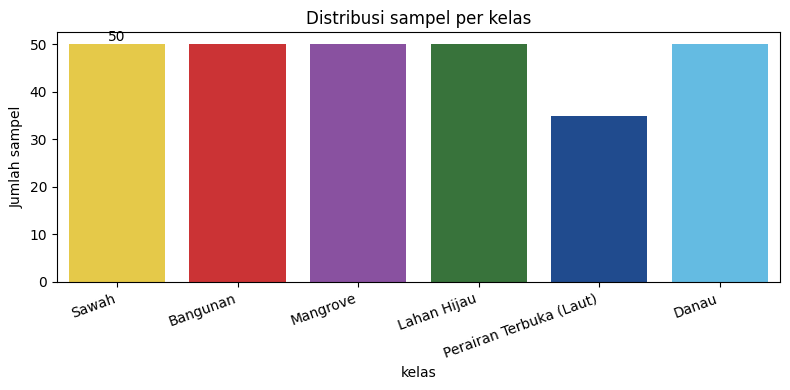

In [25]:
jml = df["kelas"].value_counts().reindex(NAMA_KELAS)
print("Jumlah kelas :", df["kelas"].nunique())
print("Jumlah data  :", len(df))
display(jml.to_frame("jumlah sampel"))

plt.figure(figsize=(8, 4))
ax = sns.barplot(x=jml.index, y=jml.values, palette=[WARNA_KELAS[k] for k in jml.index])
ax.bar_label(ax.containers[0])
plt.xticks(rotation=20, ha="right"); plt.ylabel("Jumlah sampel"); plt.title("Distribusi sampel per kelas")
plt.tight_layout(); plt.show()

## 4.2 Statistik Deskriptif Fitur
Tabel berikut menunjukkan rata-rata, simpangan baku, nilai minimum, dan maksimum seluruh fitur. Nilai rata-rata per kelas membantu melihat fitur mana yang membedakan kelas.

In [26]:
display(df[FITUR_SEMUA].describe().T.round(4))
print("\nRata-rata fitur per kelas:")
display(df.groupby("kelas")[FITUR_SEMUA].mean().reindex(NAMA_KELAS).round(3))

,count,mean,std,min,25%,50%,75%,max
B2,285.0,0.0571,0.0280,0.0211,0.0381,0.0498,0.0670,0.1912
B3,285.0,0.0756,0.0317,0.0154,0.0536,0.0742,0.0922,0.2008
B4,285.0,0.0680,0.0450,0.0099,0.0328,0.0555,0.0911,0.2448
B5,285.0,0.1082,0.0464,0.0095,0.0824,0.1129,0.1414,0.2155
B6,285.0,0.1740,0.0906,0.0044,0.1191,0.1848,0.2418,0.3574
B7,285.0,0.1973,0.1077,0.0055,0.1322,0.2002,0.2745,0.4564
B8,285.0,0.1958,0.1128,0.0048,0.0983,0.2086,0.2776,0.5312
B8A,285.0,0.2110,0.1184,0.0035,0.1434,0.2144,0.3004,0.4775
B11,285.0,0.1546,0.0904,0.0092,0.0832,0.1602,0.2294,0.3457
B12,285.0,0.1081,0.0827,0.0082,0.0426,0.0846,0.1659,0.3046



Rata-rata fitur per kelas:


,B2,B3,B4,B5,B6,B7,B8,B8A,B11,B12,NDVI,NDWI,MNDWI,NDBI,NDRE,EVI,SAVI,BSI
kelas,,,,,,,,,,,,,,,,,,
Sawah,0.052,0.080,0.073,0.130,0.234,0.269,0.268,0.293,0.207,0.117,0.568,-0.534,-0.435,-0.131,0.345,0.369,0.345,-0.071
Bangunan,0.102,0.119,0.140,0.158,0.174,0.182,0.184,0.199,0.258,0.239,0.142,-0.217,-0.369,0.166,0.074,0.089,0.081,0.164
Mangrove,0.040,0.068,0.040,0.108,0.247,0.290,0.293,0.308,0.115,0.050,0.742,-0.605,-0.237,-0.434,0.446,0.507,0.449,-0.362
Lahan Hijau,0.055,0.075,0.070,0.121,0.214,0.248,0.251,0.266,0.205,0.147,0.554,-0.525,-0.472,-0.089,0.332,0.354,0.324,-0.057
Perairan Terbuka (Laut),0.043,0.031,0.024,0.025,0.023,0.023,0.021,0.022,0.021,0.019,-0.066,0.213,0.207,0.006,-0.105,-0.007,-0.007,-0.193
Danau,0.047,0.067,0.048,0.082,0.107,0.120,0.105,0.121,0.082,0.050,0.179,-0.027,0.044,-0.081,-0.044,0.117,0.105,-0.059


## 4.3 Tanda Tangan Spektral (*Spectral Signature*)
Grafik ini memperlihatkan rata-rata reflektansi tiap kelas pada tiap band. Perhatikan pola khas berikut:
* **Vegetasi (sawah, lahan hijau, mangrove):** pantulan rendah di merah (B4, klorofil menyerap), melonjak tajam di *red edge* dan NIR (B5–B8A), lalu turun di SWIR.
* **Air (laut, danau):** reflektansi rendah dan terus menurun ke arah NIR dan SWIR, karena air menyerap hampir semua energi inframerah.
* **Bangunan:** reflektansi relatif tinggi dan datar di seluruh band, dengan SWIR yang lebih tinggi dibanding vegetasi.

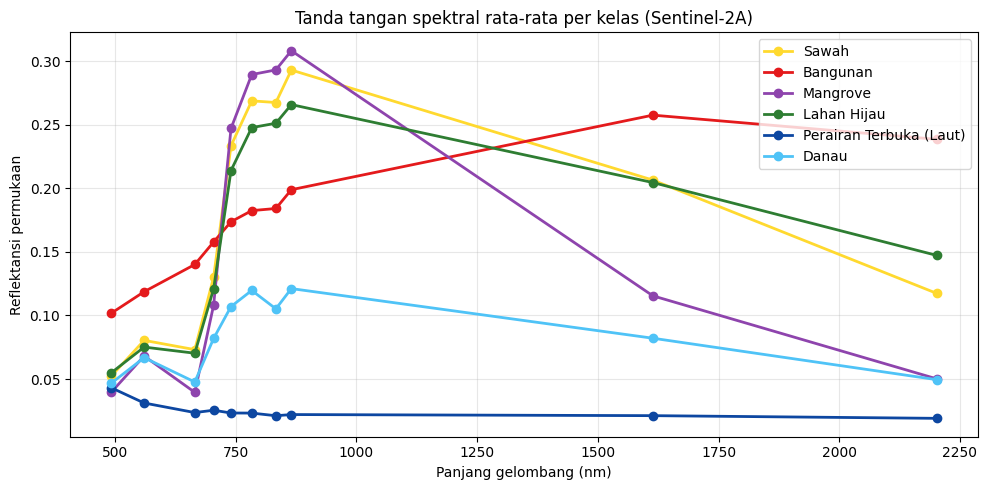

In [27]:
panjang_gelombang = [492, 560, 665, 704, 740, 783, 833, 865, 1614, 2202]
rata = df.groupby("kelas")[BAND_ASLI].mean().reindex(NAMA_KELAS)

plt.figure(figsize=(10, 5))
for k in NAMA_KELAS:
    plt.plot(panjang_gelombang, rata.loc[k].values, marker="o", lw=2, label=k, color=WARNA_KELAS[k])
plt.xlabel("Panjang gelombang (nm)"); plt.ylabel("Reflektansi permukaan")
plt.title("Tanda tangan spektral rata-rata per kelas (Sentinel-2A)")
plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.show()

## 4.4 Sebaran Indeks Spektral per Kelas
*Boxplot* menunjukkan seberapa baik sebuah indeks memisahkan kelas. Indeks yang kotaknya tidak saling tumpang tindih antar kelas adalah pembeda yang baik.

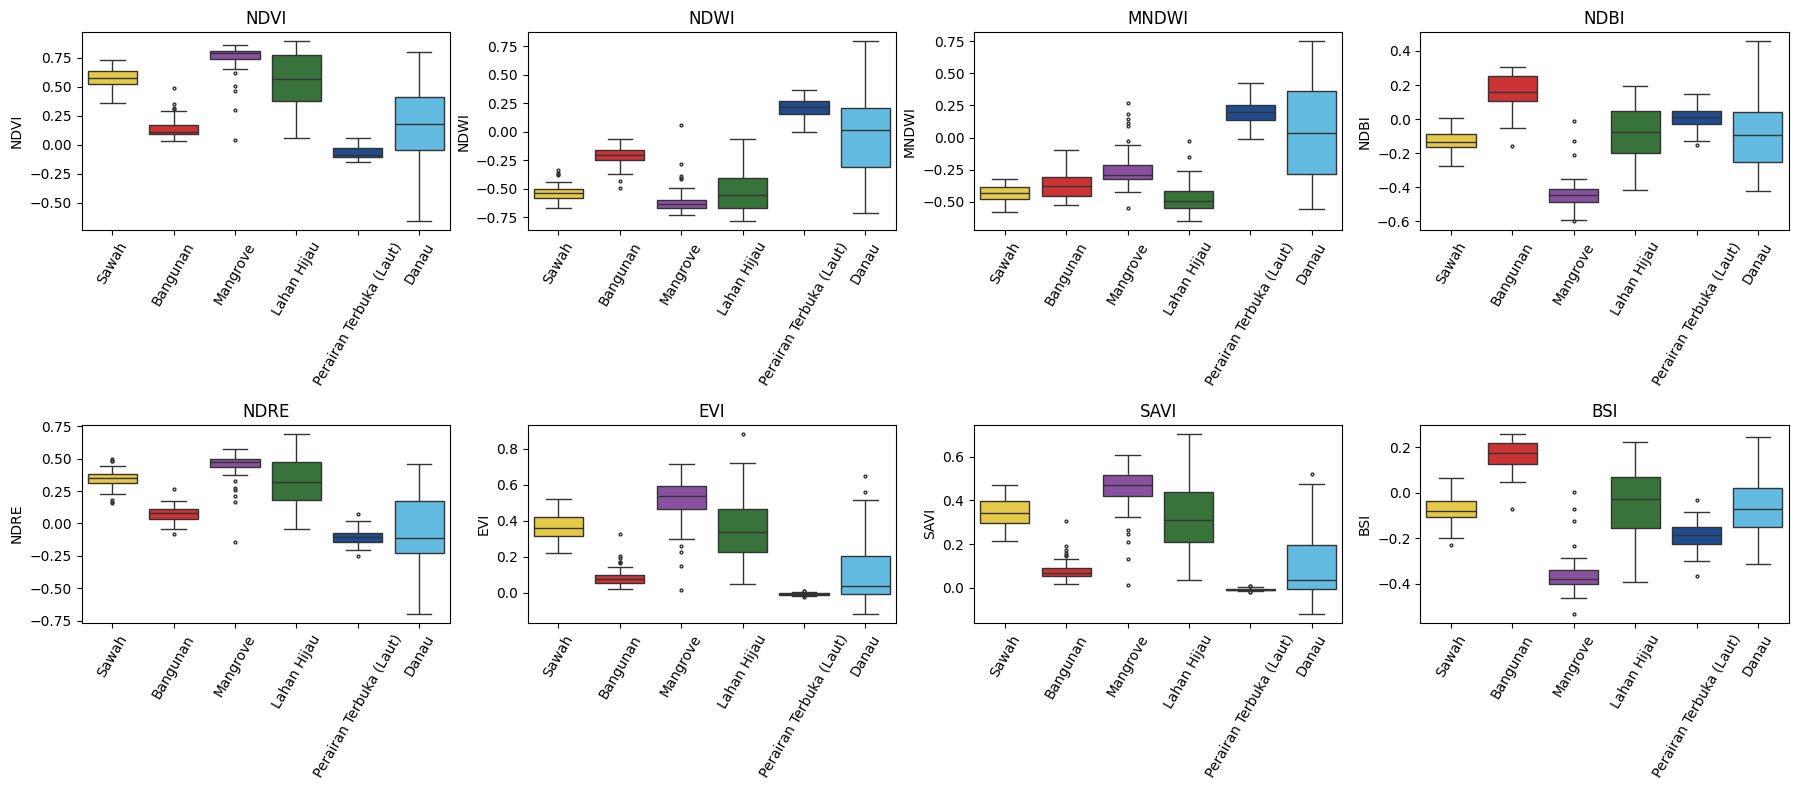

In [28]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, f in zip(axes.ravel(), INDEKS):
    sns.boxplot(data=df, x="kelas", y=f, order=NAMA_KELAS, palette=WARNA_KELAS, ax=ax, fliersize=2)
    ax.set_title(f); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

## 4.5 Korelasi Antar Fitur
Berbeda dengan Naive Bayes yang menuntut asumsi independensi bersyarat (*conditional independence*), algoritma **K-Nearest Neighbors (KNN)** bekerja berdasarkan jarak multi-dimensi (seperti Euclidean atau Manhattan distance). Namun, multikolinearitas dan terutama **perbedaan skala antarfitur** sangat mempengaruhi metrik jarak pada KNN. Nilai band reflektansi berkisar antara 0.0 s.d. 0.4, sedangkan indeks spektral seperti NDVI berkisar antara -1.0 s.d. +1.0. Jika tidak dinormalisasi, fitur dengan varians atau magnitudo lebih besar akan mendominasi perhitungan jarak. Oleh karena itu, standarisasi fitur (`StandardScaler`) menjadi tahapan wajib sebelum menghitung ketetanggaan terdekat.

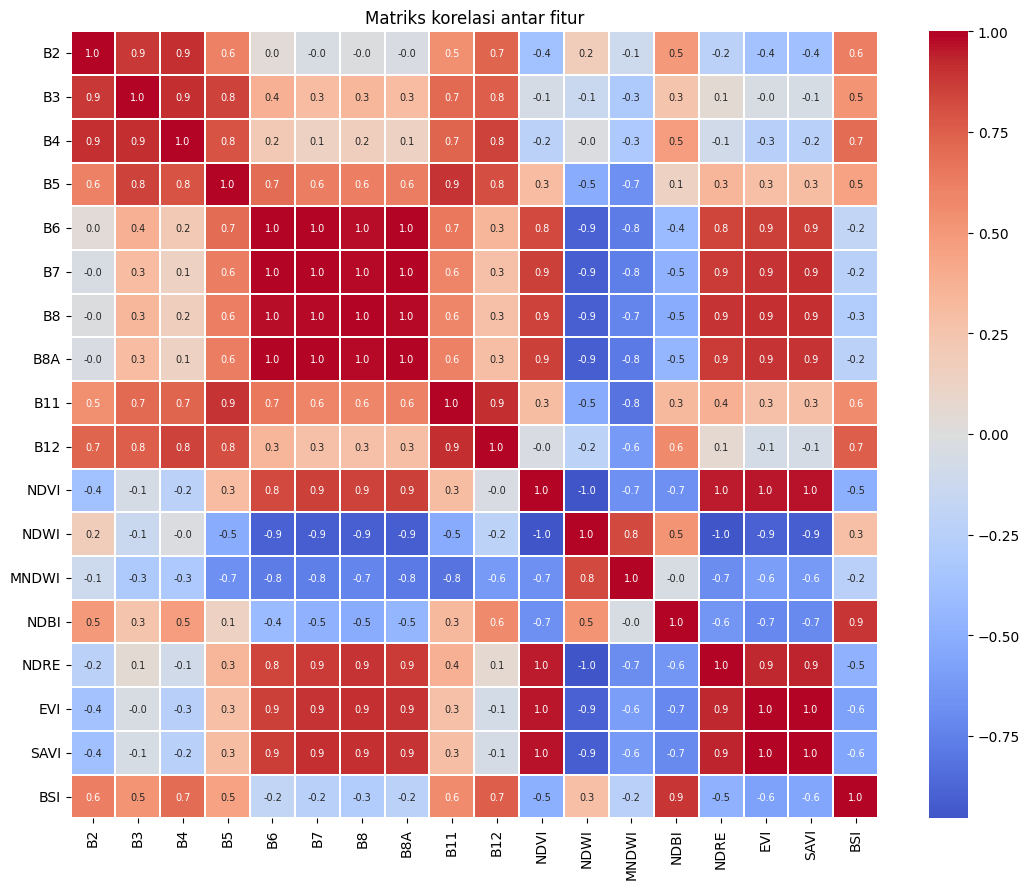

In [29]:
plt.figure(figsize=(11, 9))
sns.heatmap(df[FITUR_SEMUA].corr(), cmap="coolwarm", center=0, annot=True, fmt=".1f",
            annot_kws={"size": 7}, linewidths=.3)
plt.title("Matriks korelasi antar fitur"); plt.tight_layout(); plt.show()

---
# 5. Pemodelan Support Vector Machine (SVM)

## 5.1 Algoritma Support Vector Machine (SVM)
**Support Vector Machine (SVM)** adalah algoritma pembelajaran terbimbing yang bekerja dengan mencari *hyperplane* pemisah optimal antar kelas. Berbeda dengan KNN yang berbasis kedekatan, SVM memaksimalkan **margin** antara kelas sehingga lebih robust terhadap *noise* dan mampu menangani data berdimensi tinggi seperti citra penginderaan jauh secara efektif.

**Prinsip Kerja SVM:**
1. Mencari hyperplane dengan margin maksimal antara kelas yang berbeda
2. Data yang sulit dipisahkan secara linear diproyeksikan ke ruang dimensi lebih tinggi menggunakan **fungsi kernel**
3. Kernel **Radial Basis Function (RBF)** digunakan: $K(x_i, x_j) = \exp(-\gamma \|x_i - x_j\|^2)$

**Keunggulan SVM untuk klasifikasi lahan:**
- Efektif pada data berdimensi tinggi (18 fitur spektral + indeks)
- Robust terhadap overfitting dengan regularisasi parameter C
- Kernel RBF mampu menangkap pola non-linear pada spektrum citra satelit
- Terbukti unggul dalam klasifikasi multikelas penginderaan jauh

**Hyperparameter utama:**
- `C` (regularisasi): mengontrol trade-off antara margin dan kesalahan klasifikasi
- `gamma`: lebar kernel RBF — `scale` berarti $1 / (n\_features \times \text{var}(X))$
- `kernel`: fungsi kernel yang digunakan (`rbf`, `linear`, `poly`, dll.)


In [30]:
UKURAN_TEST = 0.20
X = df[FITUR_SEMUA]
y = df["kelas"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=UKURAN_TEST, stratify=y, random_state=SEED)

tabel_split = pd.DataFrame({
    "Total":    y.value_counts(),
    "Training": y_train.value_counts(),
    "Testing":  y_test.value_counts(),
}).reindex(NAMA_KELAS)
tabel_split.loc["TOTAL"] = tabel_split.sum()
print(f"Jumlah kelas        : {y.nunique()}")
print(f"Jumlah data training: {len(X_train)} ({len(X_train)/len(X):.0%})")
print(f"Jumlah data testing : {len(X_test)} ({len(X_test)/len(X):.0%})")
display(tabel_split.astype(int))

Jumlah kelas        : 6
Jumlah data training: 228 (80%)
Jumlah data testing : 57 (20%)


,Total,Training,Testing
kelas,,,
Sawah,50,40,10
Bangunan,50,40,10
Mangrove,50,40,10
Lahan Hijau,50,40,10
Perairan Terbuka (Laut),35,28,7
Danau,50,40,10
TOTAL,285,228,57


## 5.3 Pelatihan dan Evaluasi Model
Metrik evaluasi yang digunakan (TP = *true positive*, FP = *false positive*, FN = *false negative*):

* **Akurasi** = $\frac{\text{TP}+\text{TN}}{\text{Total}}$: proporsi prediksi yang benar secara keseluruhan.
* **Presisi** = $\frac{\text{TP}}{\text{TP}+\text{FP}}$: dari semua yang diprediksi kelas X, berapa yang benar-benar X.
* **Recall** = $\frac{\text{TP}}{\text{TP}+\text{FN}}$: dari semua yang sebenarnya kelas X, berapa yang berhasil terdeteksi.
* **F1-score** = $2 \times \frac{\text{Presisi} \times \text{Recall}}{\text{Presisi}+\text{Recall}}$: rata-rata harmonik presisi dan recall.
* **Cohen's Kappa**: mengukur kesepakatan prediksi di atas peluang acak ($>0.8$ sangat baik).
* **Confusion Matrix**: tabel silang antara kelas aktual dan prediksi untuk melihat kelas mana yang sering tertukar.

In [31]:
# Import SVM
from sklearn.svm import SVC

# Model baseline SVM (RBF kernel, C=10) dengan StandardScaler
model_baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=10, gamma="scale", probability=True, random_state=SEED))
])
model_baseline.fit(X_train, y_train)

pred_train = model_baseline.predict(X_train)
pred_test  = model_baseline.predict(X_test)

def metrik(y_true, y_pred):
    return {
        "Akurasi": accuracy_score(y_true, y_pred),
        "Kappa":   cohen_kappa_score(y_true, y_pred),
        "F1 macro": f1_score(y_true, y_pred, average="macro", zero_division=0)
    }

print("=== Model Baseline SVM (RBF, C=10) ===")
print("\n[Training]")
for k, v in metrik(y_train, pred_train).items():
    print(f"  {k}: {v:.4f}")
print("\n[Testing]")
for k, v in metrik(y_test, pred_test).items():
    print(f"  {k}: {v:.4f}")


=== Model Baseline SVM (RBF, C=10) ===

[Training]
  Akurasi: 0.9342
  Kappa: 0.9208
  F1 macro: 0.9370

[Testing]
  Akurasi: 0.8246
  Kappa: 0.7889
  F1 macro: 0.8286


**Cara membaca hasil:** SVM dengan kernel RBF mencari hyperplane non-linear yang memaksimalkan margin antara kelas. Akurasi training biasanya tidak mencapai 100% karena SVM menggunakan *soft margin* (parameter C) untuk toleransi misklasifikasi — ini justru menandakan model tidak overfitting. Performa sejati dinilai dari metrik **data testing** dan evaluasi **Repeated Cross-Validation**.


---
# 6. Eksperimen
Karena jumlah data kecil, eksperimen dievaluasi dengan **Repeated Stratified 5-Fold Cross-Validation (10 pengulangan = 50 evaluasi)** sehingga hasilnya lebih stabil daripada satu kali pembagian.

## 6.1 Eksperimen Rasio Training:Testing
Membandingkan rasio pembagian data. Setiap rasio diulang 30 kali dengan *seed* berbeda, lalu diambil rata-rata dan simpangan bakunya.

In [32]:
hasil_rasio = []
for ts in [0.10, 0.20, 0.30, 0.40]:
    skor = []
    for r in range(10):
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=ts, stratify=y, random_state=SEED + r)
        m = Pipeline([
            ("scaler", StandardScaler()),
            ("svm", SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED))
        ]).fit(X_tr, y_tr)
        skor.append(accuracy_score(y_te, m.predict(X_te)))
    hasil_rasio.append({
        "Rasio train:test": f"{int((1-ts)*100)}:{int(ts*100)}",
        "Akurasi rata-rata": np.mean(skor),
        "Std":               np.std(skor),
    })

tab_rasio = pd.DataFrame(hasil_rasio)
tab_rasio["Akurasi rata-rata"] = tab_rasio["Akurasi rata-rata"].map("{:.4f}".format)
tab_rasio["Std"]               = tab_rasio["Std"].map("{:.4f}".format)
display(tab_rasio)


,Rasio train:test,Akurasi rata-rata,Std
0,90:10,0.8759,0.0468
1,80:20,0.8632,0.0435
2,70:30,0.8767,0.0245
3,60:40,0.8728,0.0212


## 6.2 Eksperimen Kombinasi Fitur
Membandingkan apakah penambahan indeks spektral dan band Sentinel-2A meningkatkan kinerja SVM dibanding hanya memakai band mentah atau indeks saja.

In [33]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)

skenario_fitur = {
    "A. 4 band 10 m (B2,B3,B4,B8)":            ["B2", "B3", "B4", "B8"],
    "B. 10 band Sentinel-2A":                  BAND_ASLI,
    "C. 8 indeks spektral":                    INDEKS,
    "D. Indeks pilihan (NDVI,MNDWI,NDBI,BSI)": ["NDVI", "MNDWI", "NDBI", "BSI"],
    "E. Band + indeks (18 fitur)":             FITUR_SEMUA,
}
hasil_fitur = []
for nama, cols in skenario_fitur.items():
    pip = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED))
    ])
    skor = cross_val_score(pip, df[cols], y, cv=cv, scoring="accuracy", n_jobs=-1)
    hasil_fitur.append({
        "Skenario": nama,
        "Jumlah fitur": len(cols),
        "Akurasi CV mean": skor.mean(),
        "Std": skor.std(),
    })

tab_fitur = pd.DataFrame(hasil_fitur).sort_values("Akurasi CV mean", ascending=False)
tab_fitur["Akurasi CV mean"] = tab_fitur["Akurasi CV mean"].map("{:.4f}".format)
tab_fitur["Std"]             = tab_fitur["Std"].map("{:.4f}".format)
display(tab_fitur)

# Tentukan fitur terbaik dari eksperimen
BEST_FITUR_NAMA = tab_fitur.iloc[0]["Skenario"]
FITUR_FINAL_NAMA = BEST_FITUR_NAMA
FITUR_FINAL = skenario_fitur[BEST_FITUR_NAMA]
print(f"\nFitur terbaik: {BEST_FITUR_NAMA} ({len(FITUR_FINAL)} fitur)")


,Skenario,Jumlah fitur,Akurasi CV mean,Std
4,E. Band + indeks (18 fitur),18,0.8670,0.0349
1,B. 10 band Sentinel-2A,10,0.8572,0.0353
2,C. 8 indeks spektral,8,0.8295,0.0428
3,"D. Indeks pilihan (NDVI,MNDWI,NDBI,BSI)",4,0.8196,0.0406
0,"A. 4 band 10 m (B2,B3,B4,B8)",4,0.7965,0.0469



Fitur terbaik: E. Band + indeks (18 fitur) (18 fitur)


## 6.3 Eksperimen Hyperparameter SVM (C, Gamma, dan Kernel)
Kinerja model SVM sangat dipengaruhi oleh tiga hyperparameter utama:
1. **C (regularisasi):** Nilai C kecil menghasilkan margin lebih lebar (lebih toleran terhadap misklasifikasi). Nilai C besar memaksimalkan margin ketat dan berisiko overfitting.
2. **Gamma:** Menentukan lebar kernel RBF. Nilai besar → batas keputusan kompleks, risiko overfitting. Nilai kecil → model lebih smooth.
3. **Kernel:** RBF cocok untuk data non-linear multidimensi seperti citra satelit.

Pencarian hyperparameter optimal dilakukan dengan **GridSearchCV + RepeatedStratifiedKFold**.


In [34]:
from sklearn.svm import SVC

param_grid = {
    "svm__C":     [1, 10, 50, 100],
    "svm__gamma": ["scale", "auto", 0.01, 0.001],
    "svm__kernel": ["rbf", "linear"]
}
pip_grid = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(probability=True, random_state=SEED))
])
grid = GridSearchCV(pip_grid, param_grid, cv=cv, scoring="accuracy", n_jobs=-1, verbose=0)
grid.fit(df[FITUR_FINAL], y)

tab_svm = pd.DataFrame(grid.cv_results_)[[
    "param_svm__C", "param_svm__gamma", "param_svm__kernel",
    "mean_test_score", "std_test_score"
]].sort_values("mean_test_score", ascending=False).head(10).reset_index(drop=True)
tab_svm.columns = ["C", "Gamma", "Kernel", "CV Mean", "CV Std"]
tab_svm["CV Mean"] = tab_svm["CV Mean"].map("{:.4f}".format)
tab_svm["CV Std"]  = tab_svm["CV Std"].map("{:.4f}".format)
display(tab_svm)

BEST_C      = grid.best_params_["svm__C"]
BEST_GAMMA  = grid.best_params_["svm__gamma"]
BEST_KERNEL = grid.best_params_["svm__kernel"]
print(f"\nHyperparameter terbaik: C={BEST_C}, gamma={BEST_GAMMA}, kernel={BEST_KERNEL}")
print(f"CV Accuracy terbaik   : {grid.best_score_:.4f}")


,C,Gamma,Kernel,CV Mean,CV Std
0,10,auto,rbf,0.8670,0.0349
1,10,scale,rbf,0.8670,0.0349
2,100,0.01,rbf,0.8596,0.0370
3,50,0.01,rbf,0.8561,0.0335
4,1,scale,rbf,0.8540,0.0350
5,1,auto,rbf,0.8540,0.0350
6,1,0.01,linear,0.8533,0.0319
7,1,0.001,linear,0.8533,0.0319
8,1,scale,linear,0.8533,0.0319
9,1,auto,linear,0.8533,0.0319



Hyperparameter terbaik: C=10, gamma=scale, kernel=rbf
CV Accuracy terbaik   : 0.8670


## 6.4 Model Final SVM
Model final memakai kombinasi fitur dan hyperparameter SVM terbaik hasil eksperimen. Evaluasi akhir dilakukan pada data *testing* (pembagian 80:20 yang sama seperti bagian 5.2).


Akurasi testing model final SVM  : 0.8246
Kappa                            : 0.7889
F1-score macro                   : 0.8286

Classification Report:
                         precision    recall  f1-score   support

                  Sawah       0.80      0.80      0.80        10
               Bangunan       0.83      1.00      0.91        10
               Mangrove       0.62      0.50      0.56        10
            Lahan Hijau       1.00      0.80      0.89        10
Perairan Terbuka (Laut)       1.00      1.00      1.00         7
                  Danau       0.75      0.90      0.82        10

               accuracy                           0.82        57
              macro avg       0.83      0.83      0.83        57
           weighted avg       0.83      0.82      0.82        57



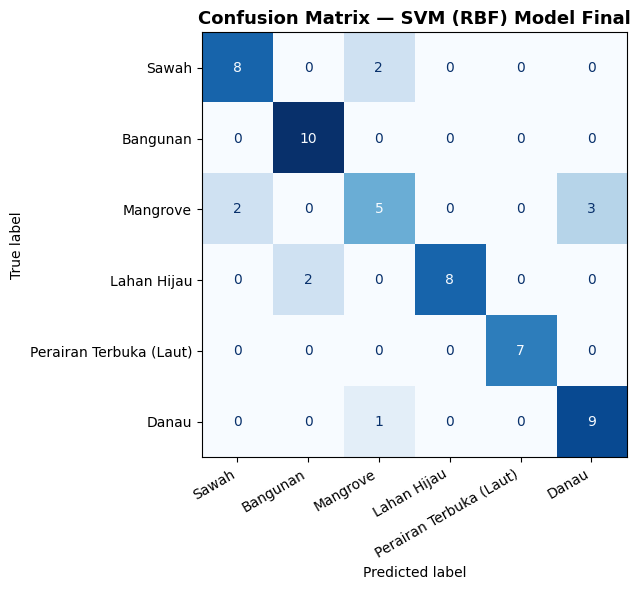

In [35]:
model_final = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel=BEST_KERNEL, C=BEST_C, gamma=BEST_GAMMA,
                probability=True, random_state=SEED))
]).fit(X_train[FITUR_FINAL], y_train)

pred_final = model_final.predict(X_test[FITUR_FINAL])

AKURASI_FINAL = accuracy_score(y_test, pred_final)
KAPPA_FINAL   = cohen_kappa_score(y_test, pred_final)
F1_FINAL      = f1_score(y_test, pred_final, average="macro", zero_division=0)

print(f"Akurasi testing model final SVM  : {AKURASI_FINAL:.4f}")
print(f"Kappa                            : {KAPPA_FINAL:.4f}")
print(f"F1-score macro                   : {F1_FINAL:.4f}")
print()
print("Classification Report:")
print(classification_report(y_test, pred_final, target_names=NAMA_KELAS, zero_division=0))

# Confusion matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_final, display_labels=NAMA_KELAS,
    cmap="Blues", ax=ax, colorbar=False
)
ax.set_title("Confusion Matrix — SVM (RBF) Model Final", fontsize=13, fontweight="bold")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


---
# 7. Peta Hasil Klasifikasi (SVM + Folium + Google Satellite)

## 7.1 Prediksi Piksel pada Area Studi
Model final SVM yang telah dilatih digunakan untuk memprediksi seluruh piksel citra pada Area of Interest (AOI). Karena area studi Jawa Timur luas, proses dilakukan secara bertahap per ubin (*tile*) untuk menghemat memori dan menstabilkan permintaan citra Copernicus.


In [36]:
import os
os.environ["CDSE_CLIENT_ID"] = "sh-186caf9f-89ee-47a7-8777-ea3c802a1c55"
os.environ["CDSE_CLIENT_SECRET"] = "UzXK59XL3TLS9LyKyfGAHyJIvgckTZFsBiU9eA64P3x8EWxwEBAB67jxJjIO0pbzg0lrwegqp5UwYIeLhdR05u"

JATIM       = [111.0, -8.85, 114.65, -6.75]   # [barat, selatan, timur, utara] - seluruh Jawa Timur
AOI         = JATIM                           # ganti dengan BBOX_SURABAYA jika ingin area lebih kecil
SKALA_PETA  = 120                             # resolusi piksel (meter). 60 m = cepat (~1,5 juta piksel)
TILE_PX     = 500                             # ukuran ubin (piksel) per permintaan
ULANGI_PETA = True                            # True: paksa lengkapi ubin yang kosong/ulang
FILE_PETA   = "label_peta.npz"

from sentinelhub.download.sentinelhub_client import SentinelHubDownloadClient
# Reset cache sesi agar token autentikasi diperbarui secara segar
SentinelHubDownloadClient._CACHED_SESSIONS.clear()
if "_cache" in globals():
    _cache.clear()

# Latih ulang model final dengan seluruh data berlabel
model_peta = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel=BEST_KERNEL, C=BEST_C, gamma=BEST_GAMMA, probability=True, random_state=SEED))
]).fit(df[FITUR_FINAL], df["kelas"])

def hex_ke_rgb(h):
    h = h.lstrip("#"); return [int(h[i:i+2], 16) for i in (0, 2, 4)]

def klasifikasi_aoi(aoi, skala, tile_px, model, fitur):
    """Mengklasifikasi AOI per ubin dengan Smart Resume dan pelaporan galat detail."""
    barat, selatan, timur, utara = aoi
    dx = skala / 111320.0                                  # meter -> derajat
    W = int(math.ceil((timur - barat) / dx))
    H = int(math.ceil((utara - selatan) / dx))
    n_tile = math.ceil(H / tile_px) * math.ceil(W / tile_px)
    print(f"Raster {W} x {H} piksel ({W*H:,} piksel), dibagi menjadi {n_tile} ubin")

    kode = {nama: i for i, nama in enumerate(NAMA_KELAS)}
    
    # Cek apakah sudah ada hasil sebagian sebelumnya untuk dilanjutkan
    label = np.full((H, W), -1, dtype=np.int8)
    if os.path.exists(FILE_PETA):
        try:
            z_lama = np.load(FILE_PETA, allow_pickle=True)
            if z_lama["label"].shape == (H, W):
                label = z_lama["label"].copy()
                terisi = np.sum(label != -1)
                print(f"Melanjutkan raster yang sudah ada ({terisi / (H*W):.1%} piksel sudah terisi)")
        except Exception:
            pass

    n, gagal = 0, []
    for r0 in range(0, H, tile_px):
        for c0 in range(0, W, tile_px):
            r1, c1 = min(r0 + tile_px, H), min(c0 + tile_px, W)
            n += 1

            # Jika ubin ini sudah terisi > 50%, lewati
            sub = label[r0:r1, c0:c1]
            if np.mean(sub != -1) > 0.5:
                print(f"\rUbin {n}/{n_tile} (sudah ada, dilewati)               ", end="")
                continue

            bbox = BBox([barat + c0*dx, utara - r1*dx, barat + c1*dx, utara - r0*dx], crs=CRS.WGS84)
            arr = None
            for percobaan in range(3):
                try:
                    arr = ambil_median(bbox, (c1 - c0, r1 - r0))
                    break
                except Exception as e:
                    # Ambil rincian respon dari server Copernicus
                    msg = str(e)
                    if hasattr(e, "request_exception") and hasattr(e.request_exception, "response"):
                        resp = e.request_exception.response
                        msg += f" | Respon Copernicus [{resp.status_code}]: {resp.text}"
                    elif hasattr(e, "response"):
                        resp = e.response
                        msg += f" | Respon Copernicus: {getattr(resp, 'text', '')}"
                    
                    if percobaan == 2:
                        gagal.append((r0, c0, msg))
                        print(f"\n[Galat Ubin {n}]: {msg[:250]}")
                    time.sleep(10)
                    
            print(f"\rUbin {n}/{n_tile}                                     ", end="")
            if arr is None:
                continue

            h, w = arr.shape[:2]
            d = tambah_indeks(pd.DataFrame(arr.reshape(-1, len(BAND_ASLI)), columns=BAND_ASLI))
            d = d.replace([np.inf, -np.inf], np.nan)
            valid = d[FITUR_SEMUA].notna().all(axis=1).values
            if valid.any():
                pred = model.predict(d.loc[valid, fitur])
                kk = np.full(h * w, -1, dtype=np.int8)
                kk[valid] = [kode[p] for p in pred]
                label[r0:r0+h, c0:c0+w] = kk.reshape(h, w)
            
            # Simpan progres parsial ke disk agar aman jika terputus
            batas_tmp = [[utara - H*dx, barat], [utara, barat + W*dx]]
            np.savez_compressed(FILE_PETA, label=label, batas=np.array(batas_tmp), aoi=np.array(AOI),
                                skala=SKALA_PETA, fitur=np.array(FITUR_FINAL))

            # Jeda 2 detik antar-ubin agar tidak memicu rate limit
            time.sleep(2)

    print()
    if gagal:
        print(f"PERINGATAN: {len(gagal)} ubin gagal diunduh.\nContoh galat:\n{gagal[0][2]}")
    batas = [[utara - H*dx, barat], [utara, barat + W*dx]]  # [[selatan, barat], [utara, timur]]
    return label, batas

# Jalankan klasifikasi dan lengkapi ubin yang tersisa
label_peta, batas_peta = klasifikasi_aoi(AOI, SKALA_PETA, TILE_PX, model_peta, FITUR_FINAL)
np.savez_compressed(FILE_PETA, label=label_peta, batas=np.array(batas_peta), aoi=np.array(AOI),
                    skala=SKALA_PETA, fitur=np.array(FITUR_FINAL))
print("Ukuran raster hasil:", label_peta.shape)


Raster 3386 x 1949 piksel (6,599,314 piksel), dibagi menjadi 28 ubin
Melanjutkan raster yang sudah ada (100.0% piksel sudah terisi)
Ubin 28/28 (sudah ada, dilewati)               
Ukuran raster hasil: (1949, 3386)


In [37]:
# --- 7.2 Post-Processing: Koreksi Spasial Danau vs Laut ---
# Air laut pesisir yang keruh sering salah terklasifikasi sebagai 'Danau' karena kemiripan spektral.
# Aturan spasial: Badan air yang terhubung langsung dengan batas laut terbuka dikoreksi menjadi Laut.
# Hanya badan air tertutup di daratan (inland) yang dipertahankan sebagai Danau.
from scipy.ndimage import label as c_label

idx_laut = NAMA_KELAS.index("Perairan Terbuka (Laut)")
idx_danau = NAMA_KELAS.index("Danau")

is_air = (label_peta == idx_laut) | (label_peta == idx_danau)
label_air, _ = c_label(is_air)

mask_tepi = np.zeros(label_peta.shape, dtype=bool)
mask_tepi[0, :] = mask_tepi[-1, :] = mask_tepi[:, 0] = mask_tepi[:, -1] = True
id_laut_terbuka = set(np.unique(label_air[mask_tepi & is_air]))

mask_terhubung_laut = np.isin(label_air, list(id_laut_terbuka))
koreksi_danau = np.sum(mask_terhubung_laut & (label_peta == idx_danau))
label_peta[mask_terhubung_laut & (label_peta == idx_danau)] = idx_laut
print(f"Koreksi pasca-klasifikasi: {koreksi_danau:,} piksel air pesisir diselaraskan menjadi Laut.")

# Simpan hasil raster yang telah dikoreksi
np.savez_compressed(FILE_PETA, label=label_peta, batas=batas_peta, aoi=np.array(AOI),
                    skala=SKALA_PETA, fitur=np.array(FITUR_FINAL))

# Ubah kode kelas -> gambar RGBA (piksel tanpa data/awan dibuat transparan)
H, W = label_peta.shape
rgba = np.zeros((H, W, 4), dtype=np.uint8)
for idx, nama in enumerate(NAMA_KELAS):
    rgba[label_peta == idx] = hex_ke_rgb(WARNA_KELAS[nama]) + [255]

# Statistik luas hasil klasifikasi pada AOI
lat_tengah = (AOI[1] + AOI[3]) / 2
luas_piksel_ha = (SKALA_PETA * SKALA_PETA * math.cos(math.radians(lat_tengah))) / 10_000
jumlah = np.bincount(label_peta[label_peta >= 0].astype(int), minlength=len(NAMA_KELAS))
tab_luas = pd.DataFrame({"Jumlah piksel": jumlah}, index=NAMA_KELAS)
tab_luas["Luas (ha)"] = (tab_luas["Jumlah piksel"] * luas_piksel_ha).round(1)
tab_luas["Persentase (%)"] = (100 * tab_luas["Jumlah piksel"] / max(tab_luas["Jumlah piksel"].sum(), 1)).round(2)
print(f"Piksel tanpa data: {(label_peta < 0).sum():,} dari {label_peta.size:,}")
display(tab_luas)

Piksel tanpa data: 351 dari 6,599,314


,Jumlah piksel,Luas (ha),Persentase (%)
Sawah,2027059,2891958.2,30.72
Bangunan,120594,172048.7,1.83
Mangrove,137889,196723.0,2.09
Lahan Hijau,1373407,1959408.0,20.81
Perairan Terbuka (Laut),2582267,3684060.7,39.13
Danau,357747,510389.4,5.42


## 7.2 Peta Interaktif Folium dengan Latar Google Satellite
Peta memakai **tile Google Maps Satellite** sebagai peta dasar (`lyrs=s`; tersedia juga *Hybrid* `lyrs=y` yang menambah label jalan/tempat). Di atasnya ditumpuk:

* **Hasil klasifikasi SVM** (overlay warna, transparansi dapat diatur),
* **Titik sampel** per kelas (opsional, dinyalakan lewat kontrol layer),
* **Legenda** kelas.


Peta disimpan: hasil_klasifikasi_svm.html (dapat ditanam di web statis lewat <iframe>)



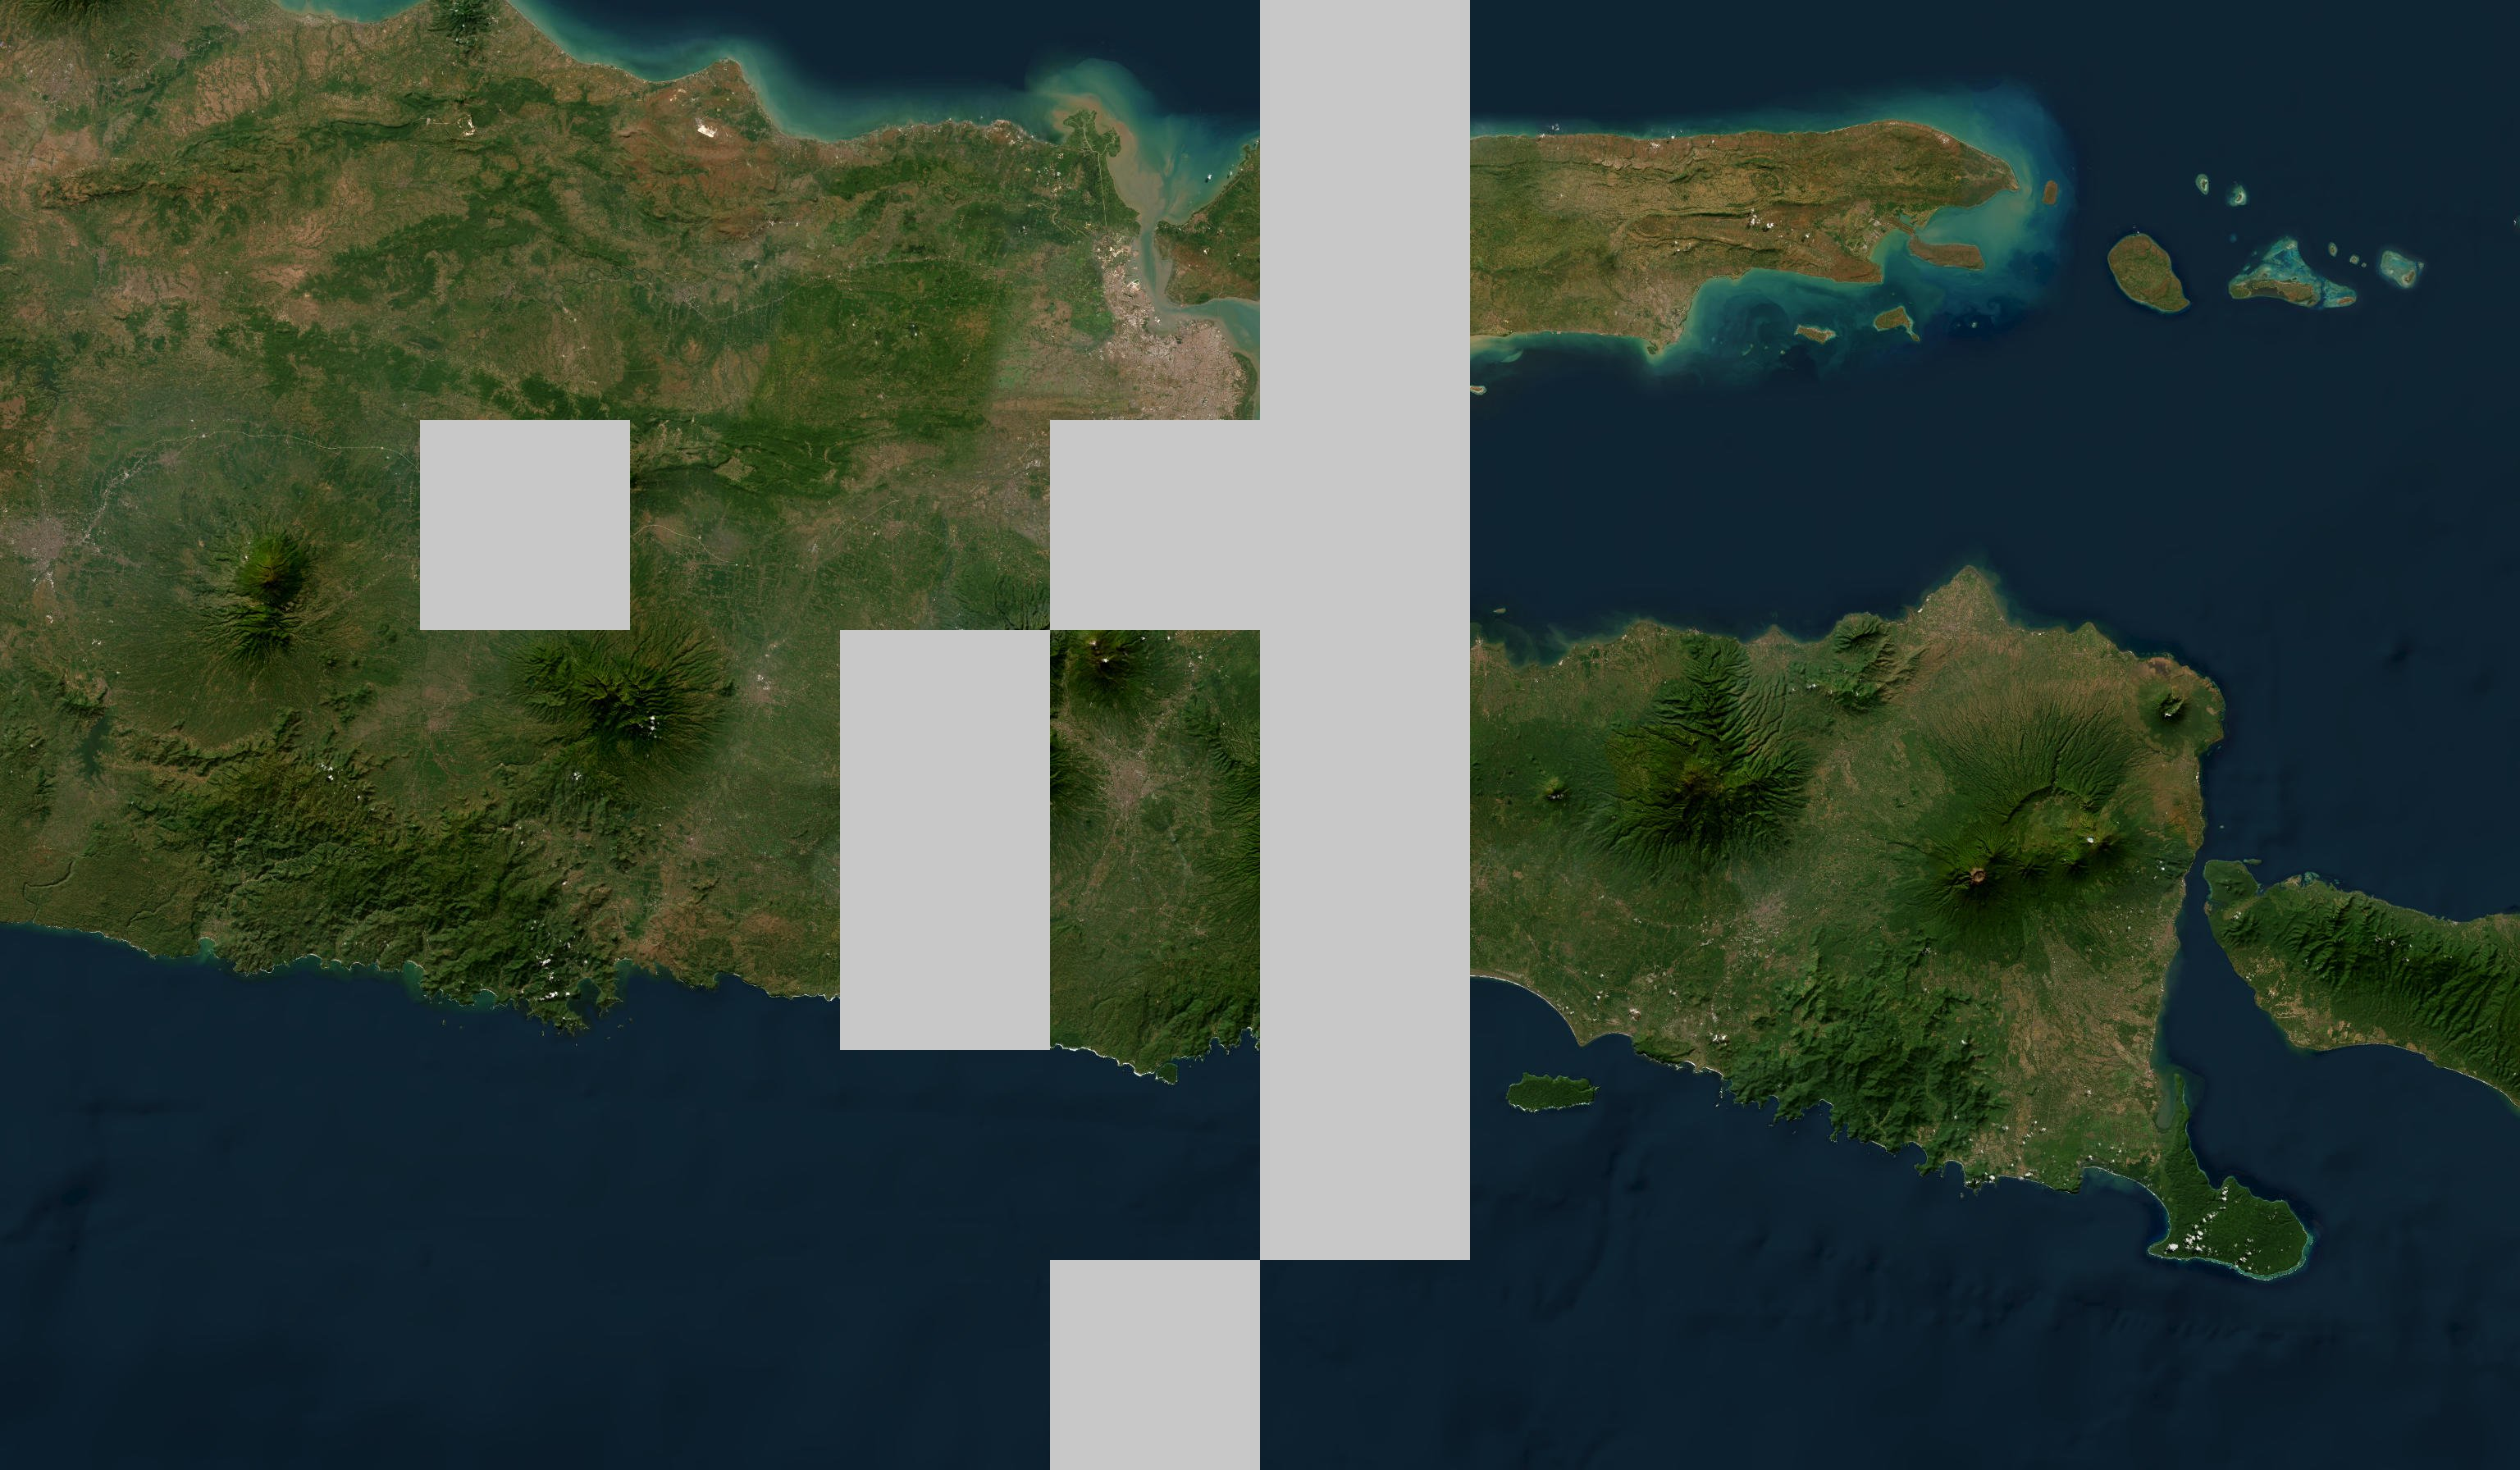
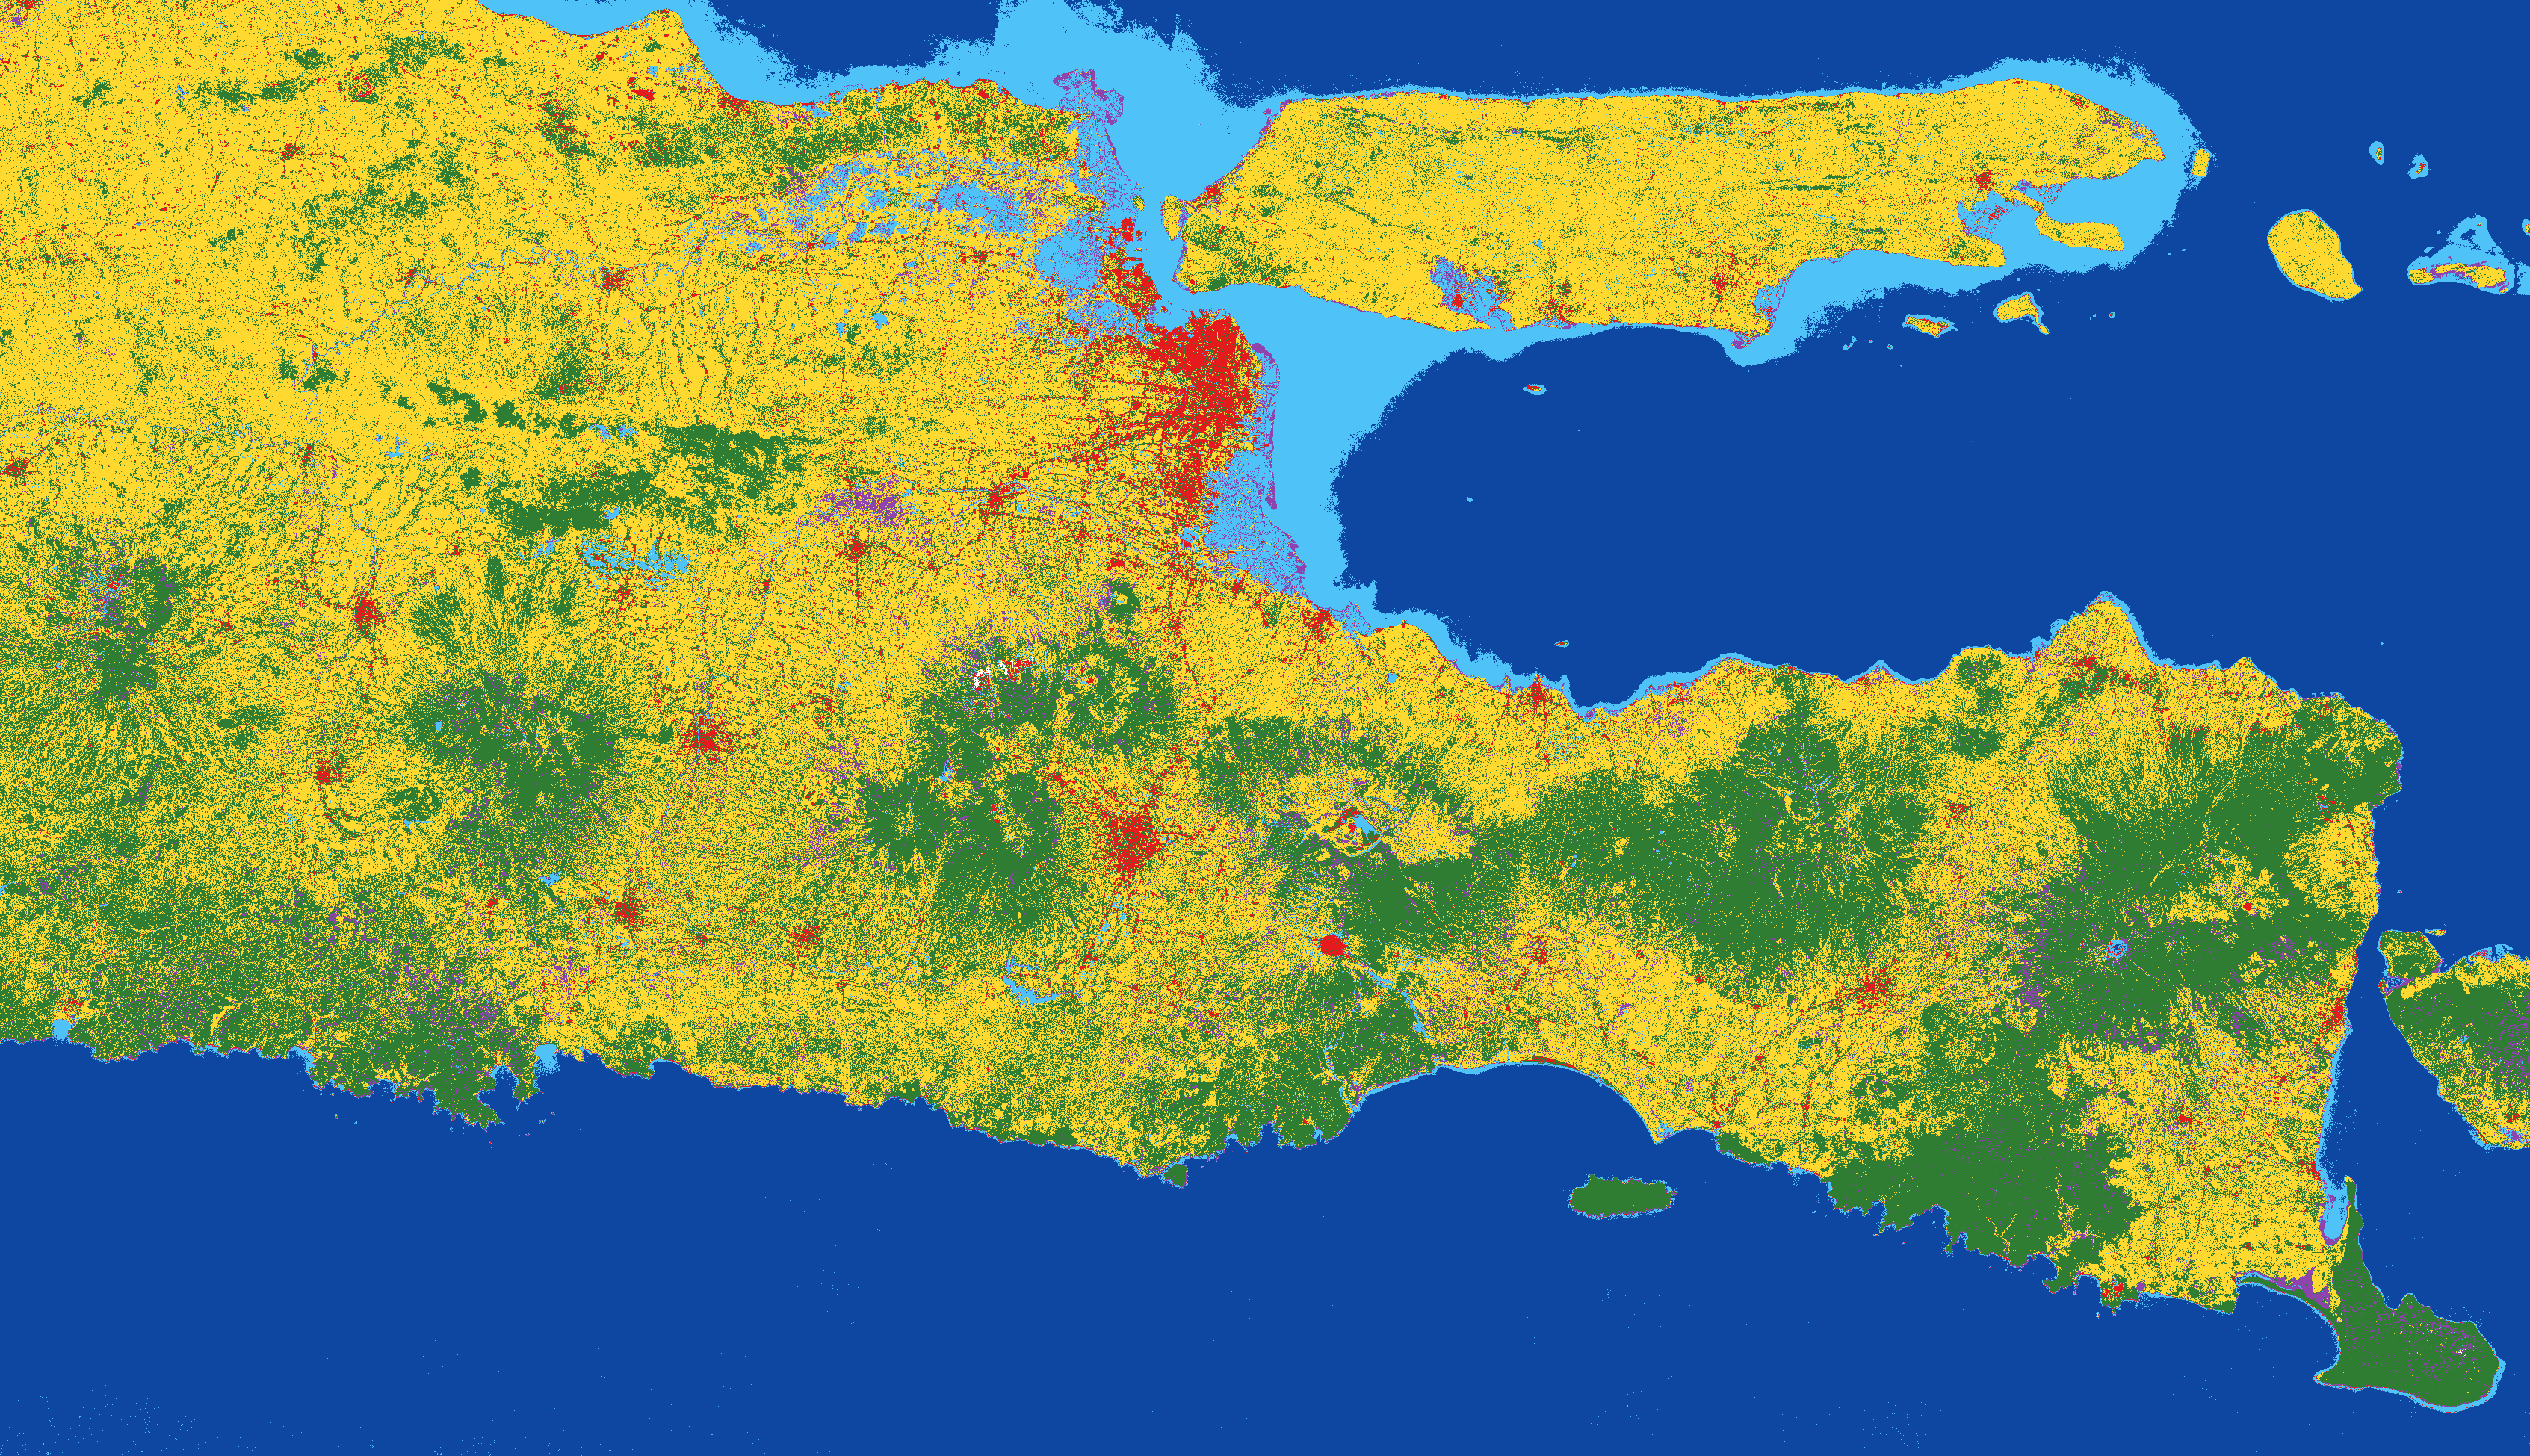

In [41]:
import math, io, requests
import folium
from folium.raster_layers import ImageOverlay
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

# --- Unduh citra satelit Esri untuk AOI, lalu tanam di peta ---
def ambil_satelit(aoi, z=10):
    n = 2 ** z
    def xy(lon, lat):
        x = (lon + 180) / 360 * n
        y = (1 - math.asinh(math.tan(math.radians(lat))) / math.pi) / 2 * n
        return x, y
    def lon_dari_x(x): return x / n * 360 - 180
    def lat_dari_y(y): return math.degrees(math.atan(math.sinh(math.pi * (1 - 2 * y / n))))

    x0, y0 = xy(aoi[0], aoi[3])
    x1, y1 = xy(aoi[2], aoi[1])
    xa, xb, ya, yb = int(x0), int(x1), int(y0), int(y1)

    mosaik = Image.new("RGB", ((xb - xa + 1) * 256, (yb - ya + 1) * 256), (200, 200, 200))
    url = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"

    def unduh(xy_):
        x, y = xy_
        try:
            r = requests.get(url.format(z=z, x=x, y=y), headers={"User-Agent": "Mozilla/5.0"}, timeout=20)
            return x, y, Image.open(io.BytesIO(r.content)).convert("RGB")
        except Exception:
            return x, y, None

    ubin = [(x, y) for x in range(xa, xb + 1) for y in range(ya, yb + 1)]
    with ThreadPoolExecutor(max_workers=8) as ex:
        for x, y, im in ex.map(unduh, ubin):
            if im is not None:
                mosaik.paste(im, ((x - xa) * 256, (y - ya) * 256))

    batas = [[lat_dari_y(yb + 1), lon_dari_x(xa)], [lat_dari_y(ya), lon_dari_x(xb + 1)]]
    return mosaik, batas

mosaik, batas_satelit = ambil_satelit(AOI, z=10)
mosaik.save("satelit_aoi.jpeg", quality=85)

# --- Peta ---
pusat = [(AOI[1] + AOI[3]) / 2, (AOI[0] + AOI[2]) / 2]
peta = folium.Map(location=pusat, zoom_start=8, tiles=None, control_scale=True)

# Basemap online
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles &copy; Esri &mdash; Source: Esri, Maxar, Earthstar Geographics",
    name="Esri Satellite (online)", max_zoom=19, overlay=False, control=True,
).add_to(peta)
folium.TileLayer(
    tiles="https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}",
    attr="Google Hybrid", name="Google Hybrid (dengan label)",
    max_zoom=20, overlay=False, control=True, show=False,
).add_to(peta)

# LAYER BAWAH: satelit tertanam
ImageOverlay(image="satelit_aoi.jpeg", bounds=batas_satelit, opacity=1,
             name="Satelit (tertanam)", interactive=False, zindex=1).add_to(peta)

# LAYER ATAS: hasil klasifikasi SVM
ImageOverlay(image=rgba, bounds=batas_peta, opacity=0.65,
             name="Hasil Klasifikasi SVM", interactive=False, zindex=2).add_to(peta)

# 1. LAYER POLIGON SAMPEL PER KELAS
for k, v in KELAS.items():
    nama = v["nama"]
    warna = WARNA_KELAS[nama]
    gdf_k = poligon[k].copy()
    gdf_k["Kelas"] = nama
    gdf_k["Poligon ID"] = list(range(len(gdf_k)))
    
    grup = folium.FeatureGroup(name=f"Kelas: {nama} ({len(gdf_k)} poligon)", show=True)
    folium.GeoJson(
        gdf_k,
        style_function=lambda feat, col=warna: {
            "fillColor": col,
            "color": "#212121",
            "weight": 1.2,
            "fillOpacity": 0.6,
        },
        tooltip=folium.GeoJsonTooltip(fields=["Kelas", "Poligon ID"], aliases=["Kelas:", "ID Poligon:"])
    ).add_to(grup)
    grup.add_to(peta)

# 2. LAYER SOROT DATA UJI
test_items = []
for idx in X_test.index:
    r = df.loc[idx]
    kid = int(r["kelas_id"])
    pid = int(r["poligon_id"])
    geom = poligon[kid].iloc[pid].geometry
    test_items.append({
        "geometry": geom,
        "Kelas": r["kelas"],
        "Poligon ID": pid
    })
gdf_test = gpd.GeoDataFrame(test_items, crs=4326)
grup_test = folium.FeatureGroup(name=f"Sorot Data Uji ({len(gdf_test)} poligon)", show=False)
folium.GeoJson(
    gdf_test,
    style_function=lambda feat: {
        "fillColor": "#00E5FF",
        "color": "#00B0FF",
        "weight": 2.5,
        "fillOpacity": 0.35,
        "dashArray": "6, 6"
    },
    tooltip=folium.GeoJsonTooltip(fields=["Kelas", "Poligon ID"], aliases=["Data Uji - Kelas:", "ID:"])
).add_to(grup_test)
grup_test.add_to(peta)

# 3. LAYER SALAH KLASIFIKASI (DENGAN HIGHLIGHT ORANGE & PIN INFO)
salah_idx = y_test.index[y_test != pred_final]
salah_items = []
for idx in salah_idx:
    r = df.loc[idx]
    kid = int(r["kelas_id"])
    pid = int(r["poligon_id"])
    geom = poligon[kid].iloc[pid].geometry
    pred_kls = pred_final[list(y_test.index).index(idx)]
    salah_items.append({
        "geometry": geom,
        "Kelas Aktual": r["kelas"],
        "Prediksi Model": pred_kls,
        "Poligon ID": pid,
        "lat": r["lat"],
        "lon": r["lon"]
    })
gdf_salah = gpd.GeoDataFrame(salah_items, crs=4326)
grup_salah = folium.FeatureGroup(name=f"Salah Klasifikasi ({len(gdf_salah)} poligon)", show=True)
folium.GeoJson(
    gdf_salah,
    style_function=lambda feat: {
        "fillColor": "#FF5722",
        "color": "#FF9100",
        "weight": 3.5,
        "fillOpacity": 0.45,
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["Kelas Aktual", "Prediksi Model", "Poligon ID"],
        aliases=["Aktual:", "Prediksi:", "ID:"]
    )
).add_to(grup_salah)

# Pin marker info orange
for _, r in gdf_salah.iterrows():
    folium.Marker(
        location=[r["lat"], r["lon"]],
        icon=folium.Icon(color="orange", icon="info-sign", prefix="glyphicon"),
        popup=folium.Popup(
            f'<div style="font-family:Arial,sans-serif;font-size:12px;min-width:160px">'
            f'<b style="color:#E65100">Salah Klasifikasi</b><br>'
            f'<b>ID Poligon:</b> {r["Poligon ID"]}<br>'
            f'<b>Aktual:</b> {r["Kelas Aktual"]}<br>'
            f'<b>Prediksi:</b> {r["Prediksi Model"]}'
            f'</div>', max_width=250
        )
    ).add_to(grup_salah)
grup_salah.add_to(peta)

# Kotak batas AOI
grup_aoi = folium.FeatureGroup(name="Batas area studi")
folium.Rectangle([[AOI[1], AOI[0]], [AOI[3], AOI[2]]], color="white", weight=1.5,
                 fill=False, dash_array="6").add_to(grup_aoi)
grup_aoi.add_to(peta)

# Legenda LULC
item = "".join(
    f'<div style="margin:2px 0"><span style="display:inline-block;width:14px;height:14px;'
    f'background:{WARNA_KELAS[k]};border:1px solid #333;margin-right:6px;vertical-align:middle"></span>{k}</div>'
    for k in NAMA_KELAS)
legenda = (f'<div style="position:fixed;bottom:30px;left:30px;z-index:9999;background:white;'
           f'padding:10px 12px;border:1px solid #888;border-radius:6px;font:13px Arial;">'
           f'<b>Legenda LULC</b><br>{item}</div>')
peta.get_root().html.add_child(folium.Element(legenda))

folium.LayerControl(collapsed=False).add_to(peta)
peta.fit_bounds([[AOI[1], AOI[0]], [AOI[3], AOI[2]]])

peta.save("hasil_klasifikasi_svm.html")
print("Peta disimpan: hasil_klasifikasi_svm.html (dapat ditanam di web statis lewat <iframe>)")
peta

---
# 8. Kesimpulan
Ringkasan berikut dibuat otomatis dari hasil eksekusi notebook.

In [40]:
terbaik_rasio = tab_rasio.sort_values("Akurasi rata-rata", ascending=False).iloc[0]
kelas_lemah = (pd.Series(f1_score(y_test, pred_final, labels=NAMA_KELAS, average=None, zero_division=0),
                         index=NAMA_KELAS).sort_values())
display(Markdown(f"""
**Ringkasan hasil**

* **Data:** {len(df)} sampel dari {df['kelas'].nunique()} kelas ({', '.join(f'{k}: {v}' for k, v in jml.items())}).
  Pembagian 80:20 menghasilkan **{len(X_train)} data training** dan **{len(X_test)} data testing**.
* **Fitur:** 10 band Sentinel-2A + 8 indeks spektral (NDVI, NDWI, MNDWI, NDBI, NDRE, EVI, SAVI, BSI).
* **Model:** Support Vector Machine (SVM RBF, C={BEST_C}, gamma={BEST_GAMMA}, kernel='{BEST_KERNEL}') dengan skenario fitur terbaik
  **{FITUR_FINAL_NAMA}**.
* **Kinerja model final (data testing):** akurasi **{AKURASI_FINAL:.2%}**, Kappa **{KAPPA_FINAL:.3f}**,
  F1 macro **{F1_FINAL:.3f}**.
* **Eksperimen rasio split:** rata-rata akurasi tertinggi pada rasio **{terbaik_rasio['Rasio train:test']}**
  ({float(terbaik_rasio['Akurasi rata-rata']):.2%}).
* **Kelas dengan F1 terendah:** **{kelas_lemah.index[0]}** ({kelas_lemah.iloc[0]:.2f}),
  lihat *confusion matrix* untuk melihat kelas mana yang tertukar.
* **Peta:** hasil klasifikasi ditampilkan pada `hasil_klasifikasi_svm.html` di atas citra Google Satellite.
"""))


**Ringkasan hasil**

* **Data:** 285 sampel dari 6 kelas (Sawah: 50, Bangunan: 50, Mangrove: 50, Lahan Hijau: 50, Perairan Terbuka (Laut): 35, Danau: 50).
  Pembagian 80:20 menghasilkan **228 data training** dan **57 data testing**.
* **Fitur:** 10 band Sentinel-2A + 8 indeks spektral (NDVI, NDWI, MNDWI, NDBI, NDRE, EVI, SAVI, BSI).
* **Model:** Support Vector Machine (SVM RBF, C=10, gamma=scale, kernel='rbf') dengan skenario fitur terbaik
  **E. Band + indeks (18 fitur)**.
* **Kinerja model final (data testing):** akurasi **82.46%**, Kappa **0.789**,
  F1 macro **0.829**.
* **Eksperimen rasio split:** rata-rata akurasi tertinggi pada rasio **70:30**
  (87.67%).
* **Kelas dengan F1 terendah:** **Lahan Hijau** (0.56),
  lihat *confusion matrix* untuk melihat kelas mana yang tertukar.
* **Peta:** hasil klasifikasi ditampilkan pada `hasil_klasifikasi_svm.html` di atas citra Google Satellite.


### Catatan dan Keterbatasan
1. **Penskalaan Fitur (*Feature Scaling*)**: SVM sangat bergantung pada skala fitur untuk perhitungan jarak kernel. Penggunaan `StandardScaler` sangat esensial agar fitur bernilai besar tidak mendominasi fitur bernilai kecil.
2. **Keseimbangan Sampel**: Target sampel diperbarui dan diseimbangkan (Sawah 50, Bangunan 50, Mangrove 50, Lahan Hijau 50, Danau 50, Laut 35: total 285 sampel). Penambahan sampel Danau dan Laut krusial untuk mencegah dominasi kelas mayoritas.
3. **Pemilihan Kernel**: Kernel RBF dipilih karena mampu menangkap pola non-linear pada reflektansi spektral yang tidak dapat dipisahkan secara linear. Kernel linear dapat menjadi alternatif bila kelas lebih mudah dipisahkan.
4. **Interpretabilitas**: SVM kurang interpretatif dibanding Decision Tree, namun memberikan akurasi generalisasi yang lebih tinggi — sesuai tujuan klasifikasi tutupan lahan otomatis.
5. **Kompleksitas Komputasi**: SVM memiliki kompleksitas $O(n^2)$–$O(n^3)$ pada training. Untuk dataset lebih besar, pertimbangkan `LinearSVC` atau kernel approximation (`Nystroem`).
6. **Validasi Lapangan**: Hasil klasifikasi disarankan divalidasi dengan data lapangan (ground truth GPS) untuk memastikan akurasi peta.
